# 📈 Financial Market Forecasting & Anomaly Detection

This notebook implements a two-phase machine learning pipeline for:

1. **Stock Price Trend Prediction** — using Yahoo Finance daily stock data and crypto market data  
2. **Fraud / Anomaly Detection** — using the Credit Card Fraud dataset

---

### Datasets
| Dataset | Source | Task |
|---|---|---|
| Yahoo Finance All-Stocks | Kaggle | Stock return regression |
| Credit Card Fraud | Kaggle (ULB) | Fraud classification |
| Crypto Market Data | Kaggle | Crypto return regression |

---

### Pipeline Overview

**Phase 1 — Classical ML**  
EDA → Feature Engineering (RSI, MACD, ATR) → KNN Regressor → Naïve Bayes Classifier → PCA → Ensemble Regressors (XGBoost, Random Forest) with Optuna hyperparameter tuning

**Phase 2 — Deep Learning**  
1D-CNN for time-series pattern recognition → AutoEncoder for unsupervised fraud/anomaly detection → Transfer Learning (AAPL → TSLA)


---
## Step 1 — Imports & Configuration

All required libraries are imported here. This is the single entry point for dependencies.


In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input, Dense, Conv1D, MaxPooling1D,
    Flatten, Dropout, BatchNormalization
)

from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

import optuna

warnings.filterwarnings("ignore")
print(f"TensorFlow version : {tf.__version__}")
print(f"GPU available      : {tf.config.list_physical_devices('GPU')}")


2026-04-20 16:26:24.287487: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776702384.578888      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776702384.655190      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776702385.317275      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776702385.317328      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776702385.317331      23 computation_placer.cc:177] computation placer alr

TensorFlow version : 2.19.0
GPU available      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Step 2 — Data Collection & Loading

### Datasets Used
- **Yahoo Finance** — daily OHLCV data for all stocks, stored as one CSV per ticker
- **Credit Card Fraud** — anonymised transaction records with PCA-transformed features (V1–V28) plus `Amount`, `Time`, and `Class`
- **Crypto Market** — daily OHLCV + Market Cap data for multiple cryptocurrencies

Each dataset is loaded into a dedicated DataFrame (`yahoo_data`, `fraud_data`, `crypto_df`) that is kept intact throughout the notebook.


In [2]:
#  Yahoo Finance 
yahoo_path = "/kaggle/input/datasets/tanavbajaj/yahoo-finance-all-stocks-dataset-daily-update/*.csv"
files = glob.glob(yahoo_path)

yahoo_df_list = []
for file in files:
    tmp = pd.read_csv(file)
    tmp["Ticker"] = os.path.basename(file).replace(".csv", "")
    yahoo_df_list.append(tmp)

yahoo_data = pd.concat(yahoo_df_list, ignore_index=True)
yahoo_data["Date"] = pd.to_datetime(yahoo_data["Date"])

print(f"Yahoo Finance — shape : {yahoo_data.shape}")
print(yahoo_data.head())


Yahoo Finance — shape : (4208047, 9)
                        Date       Open       High        Low      Close  \
0  2020-03-19 00:00:00-04:00  38.145452  43.867270  38.145452  43.152042   
1  2020-03-20 00:00:00-04:00  42.923174  43.876810  42.913639  42.913639   
2  2020-03-23 00:00:00-04:00  40.052727  40.052727  38.126381  38.145454   
3  2020-03-24 00:00:00-04:00  38.145454  38.145454  37.191818  38.145454   
4  2020-03-25 00:00:00-04:00  38.145456  42.722910  36.238183  39.108627   

   Volume  Dividends  Stock Splits Ticker  
0    7000        0.0           0.0   OTIS  
1    3600        0.0           0.0   OTIS  
2   11900        0.0           0.0   OTIS  
3   77800        0.0           0.0   OTIS  
4    7000        0.0           0.0   OTIS  


In [3]:
#  Credit Card Fraud 
fraud_path = "/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv"
fraud_data = pd.read_csv(fraud_path)

print(f"Fraud dataset — shape : {fraud_data.shape}")
print(f"Class distribution :\n{fraud_data['Class'].value_counts()}\n")
print(fraud_data.head())


Fraud dataset — shape : (284807, 31)
Class distribution :
Class
0    284315
1       492
Name: count, dtype: int64

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376  

In [4]:
#  Crypto Market 
crypto_path = "/kaggle/input/datasets/anasshahid88/crypto-market-data/**/*.csv"
files = glob.glob(crypto_path, recursive=True)

crypto_df_list = []
for file in files:
    tmp = pd.read_csv(file)
    tmp["Ticker"] = os.path.basename(file).replace(".csv", "")
    crypto_df_list.append(tmp)

crypto_df = pd.concat(crypto_df_list, ignore_index=True)

# Numeric columns may contain comma-formatted strings — clean them
numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Market Cap"]
for col in numeric_cols:
    if col in crypto_df.columns:
        crypto_df[col] = (
            crypto_df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
        )
        crypto_df[col] = pd.to_numeric(crypto_df[col], errors="coerce")

crypto_df["Date"] = pd.to_datetime(crypto_df["Date"], format="mixed")
crypto_df = crypto_df.sort_values(["Ticker", "Date"]).reset_index(drop=True)

print(f"Crypto dataset — shape : {crypto_df.shape}")
print(f"\nDtypes:\n{crypto_df.dtypes}")
print(f"\n{crypto_df.head()}")


Crypto dataset — shape : (13453, 8)

Dtypes:
Date          datetime64[ns]
Open                 float64
High                 float64
Low                  float64
Close                float64
Volume               float64
Market Cap           float64
Ticker                object
dtype: object

        Date    Open    High     Low   Close  Volume    Market Cap  \
0 2013-05-01  139.00  139.89  107.72  116.99     NaN  1.542820e+09   
1 2013-05-02  116.38  125.60   92.28  105.21     NaN  1.292190e+09   
2 2013-05-03  106.25  108.13   79.10   97.75     NaN  1.180070e+09   
3 2013-05-04   98.10  115.00   92.50  112.50     NaN  1.089890e+09   
4 2013-05-05  112.90  118.80  107.14  115.91     NaN  1.254760e+09   

                   Ticker  
0  CoinMarketData-bitcoin  
1  CoinMarketData-bitcoin  
2  CoinMarketData-bitcoin  
3  CoinMarketData-bitcoin  
4  CoinMarketData-bitcoin  


---
## Step 3 — Exploratory Data Analysis (EDA)

**Objective:** Understand the structure, statistical properties, and visual patterns of each dataset before modeling.

**Process:**  
- Inspect shapes, data types, and missing values  
- Analyse distributions and detect outliers  
- Visualise correlations and class balance  
- Compute rolling statistics and volatility metrics


### Part A — Yahoo Finance Stocks

In [5]:
print(f"Shape : {yahoo_data.shape}")
print(f"Columns : {yahoo_data.columns.tolist()}")


Shape : (4208047, 9)
Columns : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits', 'Ticker']


In [6]:
yahoo_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4208047 entries, 0 to 4208046
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Date          object 
 1   Open          float64
 2   High          float64
 3   Low           float64
 4   Close         float64
 5   Volume        int64  
 6   Dividends     float64
 7   Stock Splits  float64
 8   Ticker        object 
dtypes: float64(6), int64(1), object(2)
memory usage: 288.9+ MB


In [7]:
yahoo_data.describe()


,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06
mean,4.441393e+01,4.504356e+01,4.397453e+01,4.452156e+01,5.289525e+06,3.318746e-03,7.176755e-04
std,1.251266e+02,1.266407e+02,1.235601e+02,1.251297e+02,2.858712e+07,9.130420e-02,4.845057e-02
min,0.000000e+00,1.677443e-03,1.677444e-03,1.708315e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.050718e+00,4.227751e+00,4.113196e+00,4.173002e+00,4.655000e+05,0.000000e+00,0.000000e+00
50%,1.677780e+01,1.703905e+01,1.655592e+01,1.680335e+01,1.384800e+06,0.000000e+00,0.000000e+00
75%,4.464000e+01,4.514003e+01,4.412500e+01,4.464344e+01,3.670228e+06,0.000000e+00,0.000000e+00
max,6.490260e+03,6.525000e+03,6.405000e+03,6.509350e+03,7.421641e+09,1.037500e+02,5.000000e+01


In [8]:
print(f"Missing values : {yahoo_data.isna().sum().sum()}")
print(f"Duplicate rows : {yahoo_data.duplicated().sum()}")


Missing values : 0
Duplicate rows : 0


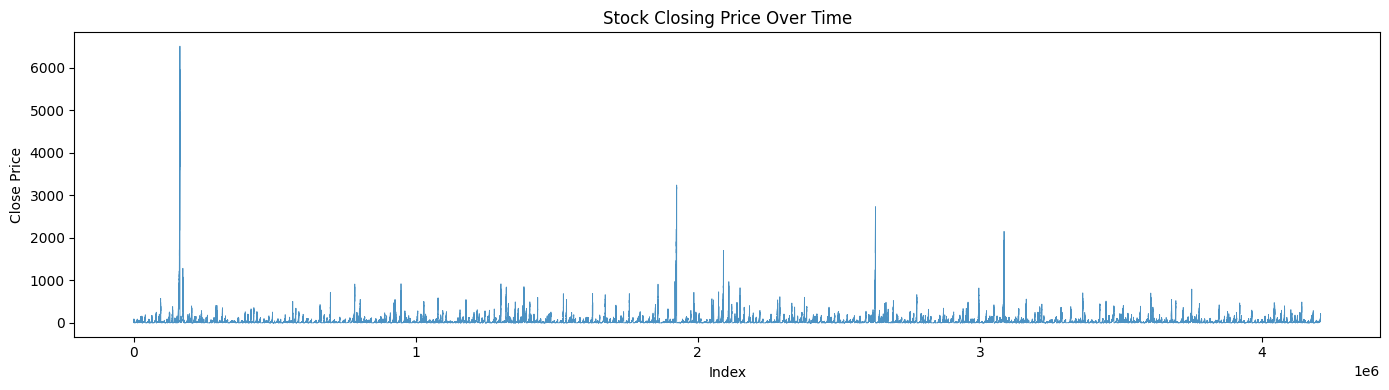

In [9]:
# Closing price over time

plt.figure(figsize=(14, 4))
plt.plot(yahoo_data["Close"], linewidth=0.6, alpha=0.8)
plt.title("Stock Closing Price Over Time")
plt.xlabel("Index")
plt.ylabel("Close Price")
plt.tight_layout()
plt.show()


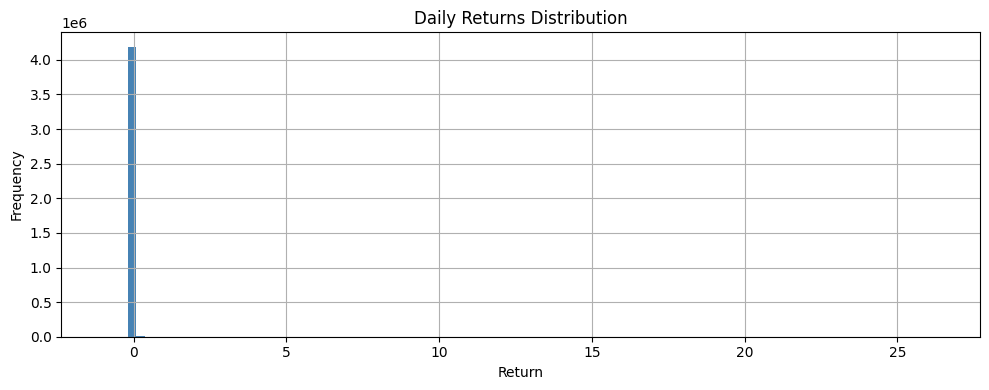

In [10]:
# Daily returns distribution

yahoo_data["returns"] = yahoo_data["Close"].pct_change()

plt.figure(figsize=(10, 4))
yahoo_data["returns"].hist(bins=100, edgecolor="none", color="steelblue")
plt.title("Daily Returns Distribution")
plt.xlabel("Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


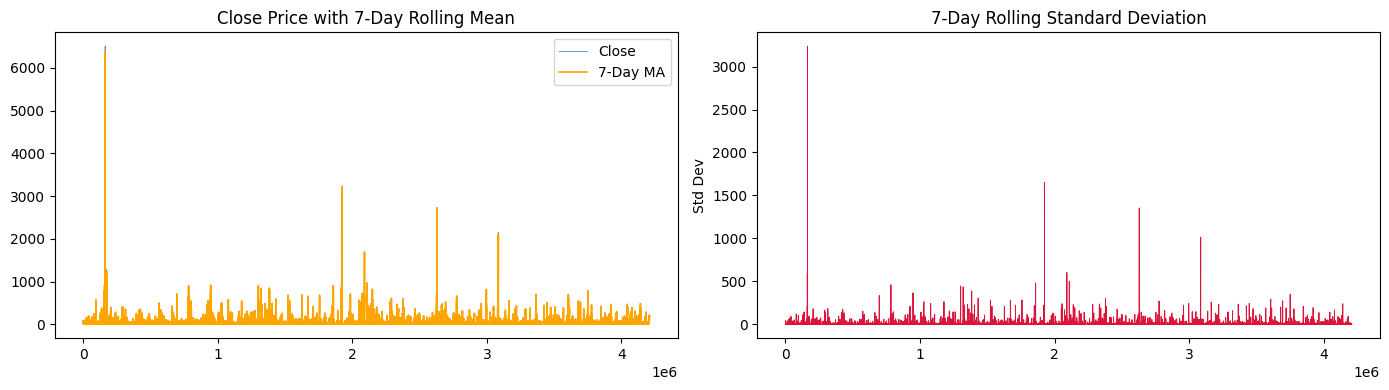

In [11]:
# Rolling statistics

yahoo_data["rolling_mean_7"] = yahoo_data["Close"].rolling(7).mean()
yahoo_data["rolling_std_7"]  = yahoo_data["Close"].rolling(7).std()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(yahoo_data["Close"],         label="Close",        linewidth=0.6, alpha=0.8)
axes[0].plot(yahoo_data["rolling_mean_7"],label="7-Day MA",     linewidth=1.2, color="orange")
axes[0].set_title("Close Price with 7-Day Rolling Mean")
axes[0].legend()

axes[1].plot(yahoo_data["rolling_std_7"], color="crimson", linewidth=0.7)
axes[1].set_title("7-Day Rolling Standard Deviation")
axes[1].set_ylabel("Std Dev")

plt.tight_layout()
plt.show()


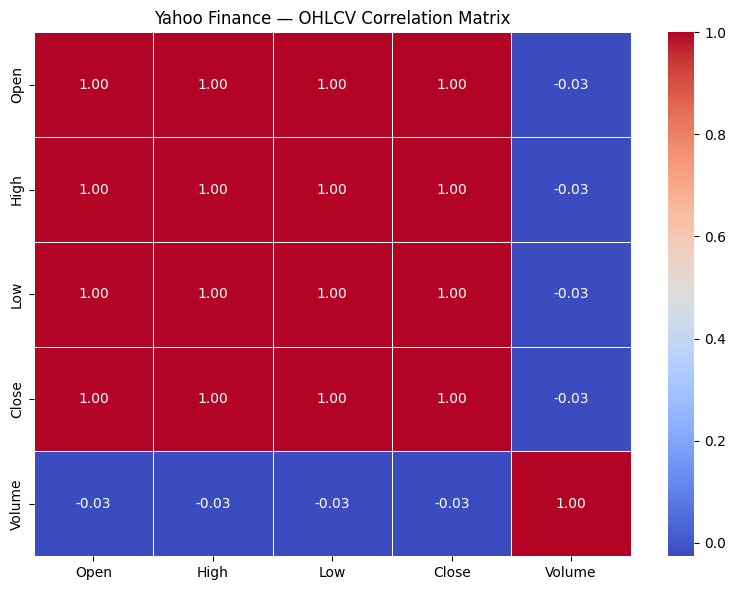

In [12]:
# Correlation heatmap for OHLCV features

plt.figure(figsize=(8, 6))
sns.heatmap(
    yahoo_data[["Open", "High", "Low", "Close", "Volume"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5
)
plt.title("Yahoo Finance — OHLCV Correlation Matrix")
plt.tight_layout()
plt.show()



### Part B — Credit Card Fraud


In [13]:
print(f"Shape : {fraud_data.shape}")
print(f"Columns : {fraud_data.columns.tolist()}")


Shape : (284807, 31)
Columns : ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [14]:
fraud_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [15]:
fraud_data.describe()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [16]:
print(f"Missing values : {fraud_data.isna().sum().sum()}")
print(f"Duplicate rows : {fraud_data.duplicated().sum()}")


Missing values : 0
Duplicate rows : 1081


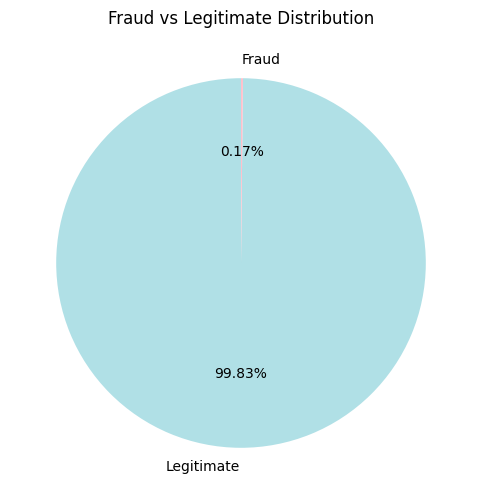

In [17]:
# Class distribution pie chart
counts = fraud_data["Class"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    counts,
    labels=["Legitimate", "Fraud"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#B0E0E6", "#FFC0CB"]
)
plt.title("Fraud vs Legitimate Distribution")
plt.show()


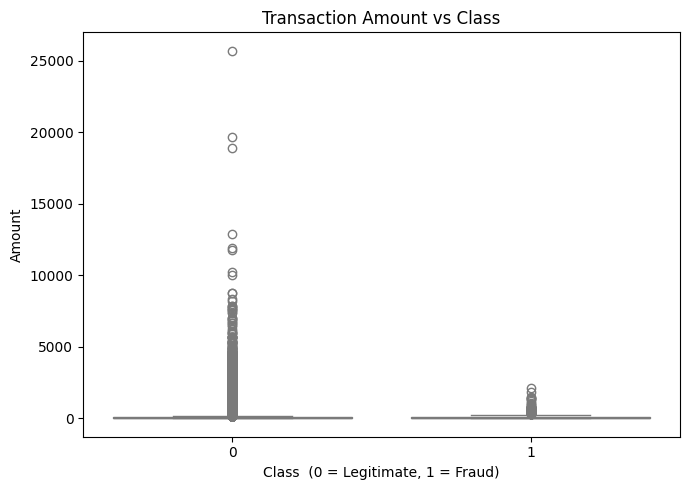

In [18]:
# Transaction amount vs class

plt.figure(figsize=(7, 5))
sns.boxplot(x="Class", y="Amount", data=fraud_data, palette=["#B0E0E6", "#FFC0CB"])
plt.title("Transaction Amount vs Class")
plt.xlabel("Class  (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()


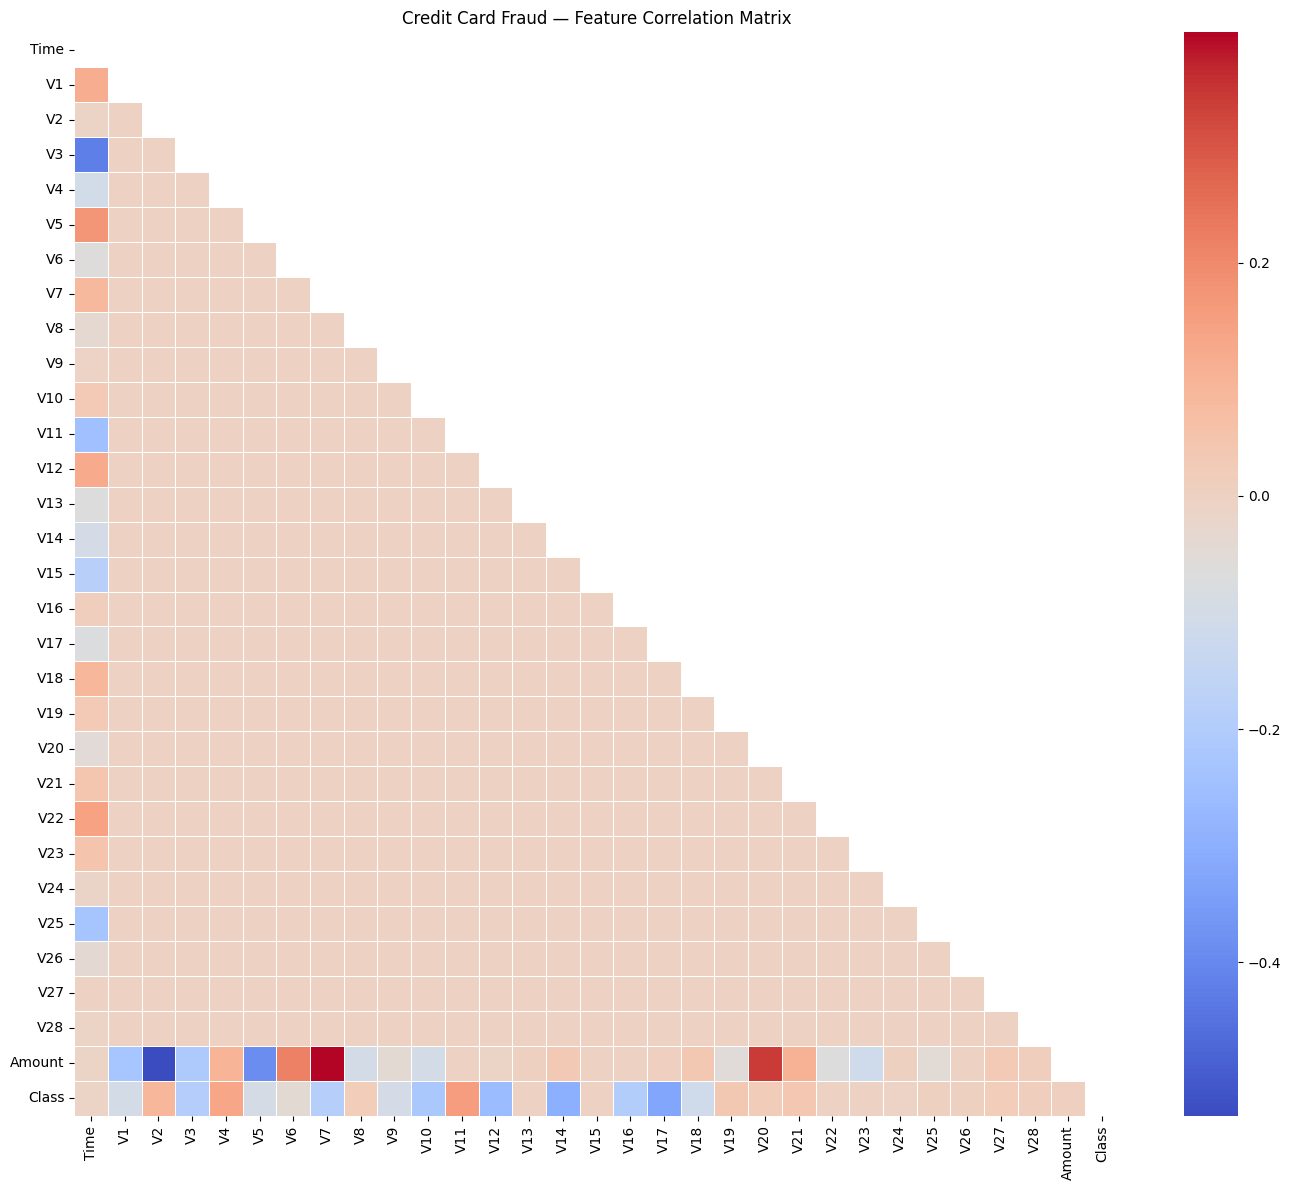

In [19]:
# Correlation heatmap (upper triangle masked)

corr = fraud_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, annot=False, cmap="coolwarm",
    mask=mask, linewidths=0.4
)
plt.title("Credit Card Fraud — Feature Correlation Matrix")
plt.tight_layout()
plt.show()



### Part C — Crypto Market


In [20]:
print(f"Shape : {crypto_df.shape}")
print(f"Columns : {crypto_df.columns.tolist()}")


Shape : (13453, 8)
Columns : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Market Cap', 'Ticker']


In [21]:
crypto_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13453 entries, 0 to 13452
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        13453 non-null  datetime64[ns]
 1   Open        13453 non-null  float64       
 2   High        13453 non-null  float64       
 3   Low         13453 non-null  float64       
 4   Close       13453 non-null  float64       
 5   Volume      12828 non-null  float64       
 6   Market Cap  13374 non-null  float64       
 7   Ticker      13453 non-null  object        
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 840.9+ KB


In [22]:
crypto_df.describe()


,Date,Open,High,Low,Close,Volume,Market Cap
count,13453,13453.000000,13453.000000,13453.000000,13453.000000,1.282800e+04,1.337400e+04
mean,2016-07-07 19:28:45.741470464,299.132920,311.429246,285.970399,299.948592,3.089217e+08,7.073517e+09
min,2013-05-01 00:00:00,0.000002,0.000003,0.000002,0.000002,3.000000e+00,1.005000e+04
25%,2015-07-01 00:00:00,0.010820,0.011613,0.010339,0.010918,2.226735e+05,4.208200e+07
50%,2016-10-12 00:00:00,2.760000,2.860000,2.660000,2.760000,5.405880e+06,2.711055e+08
75%,2017-09-09 00:00:00,46.870000,49.090000,44.790000,47.220000,8.489150e+07,3.832698e+09
max,2018-05-07 00:00:00,19475.800000,20089.000000,18974.100000,19497.400000,2.384090e+10,3.261410e+11
std,NaN,1356.417180,1414.291034,1288.089016,1358.520271,1.301536e+09,2.454509e+10


In [23]:
print(f"Missing values : {crypto_df.isna().sum().sum()}")
print(f"Duplicate rows : {crypto_df.duplicated().sum()}")


Missing values : 704
Duplicate rows : 0


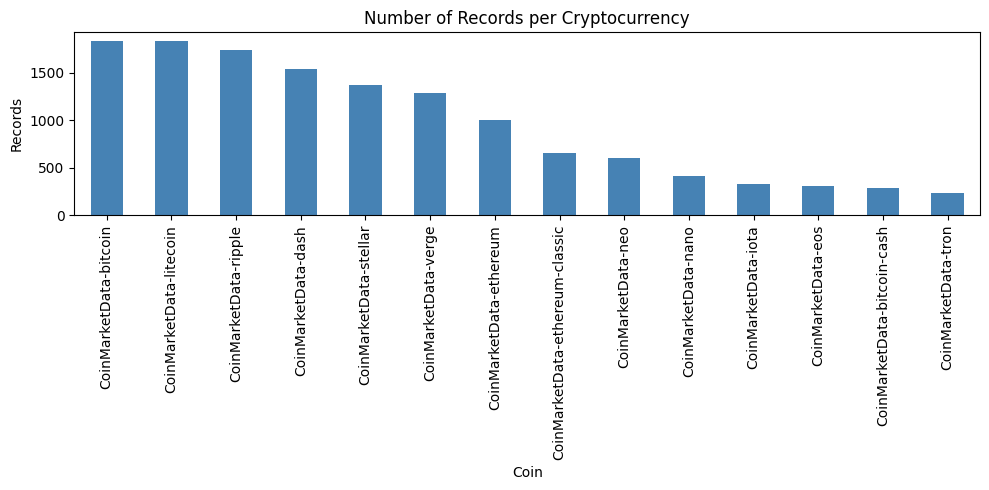

In [24]:
# Records per coin

plt.figure(figsize=(10, 5))
crypto_df["Ticker"].value_counts().plot(kind="bar", color="steelblue", edgecolor="none")
plt.title("Number of Records per Cryptocurrency")
plt.xlabel("Coin")
plt.ylabel("Records")
plt.tight_layout()
plt.show()


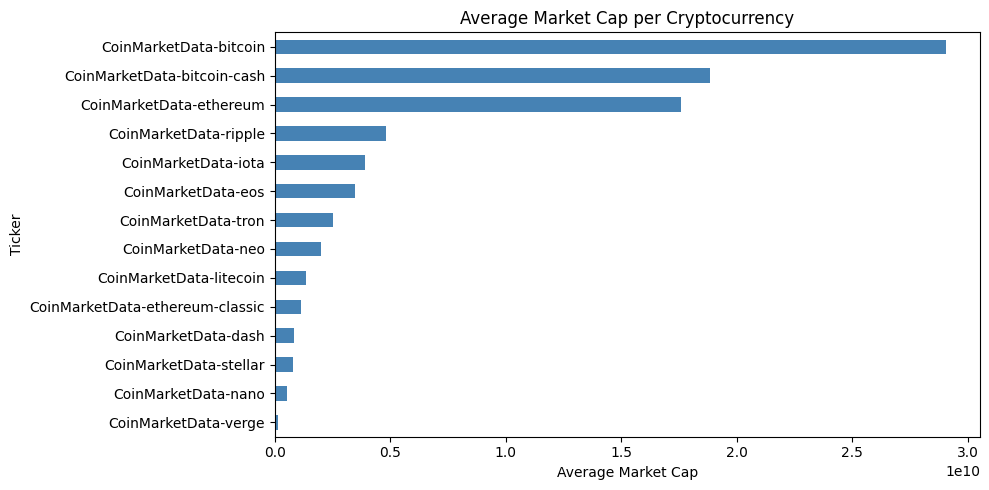

In [25]:
# Average Market Cap per coin

plt.figure(figsize=(10, 5))
crypto_df.groupby("Ticker")["Market Cap"].mean().sort_values().plot(
    kind="barh", color="steelblue", edgecolor="none"
)
plt.title("Average Market Cap per Cryptocurrency")
plt.xlabel("Average Market Cap")
plt.tight_layout()
plt.show()


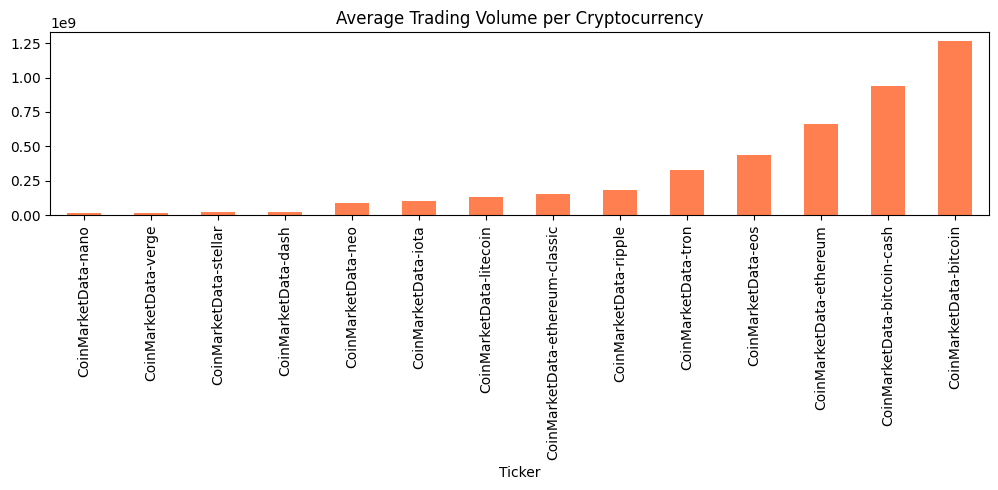

In [26]:
# Average Trading Volume per coin

plt.figure(figsize=(10, 5))
crypto_df.groupby("Ticker")["Volume"].mean().sort_values().plot(
    kind="bar", color="coral", edgecolor="none"
)
plt.title("Average Trading Volume per Cryptocurrency")
plt.tight_layout()
plt.show()


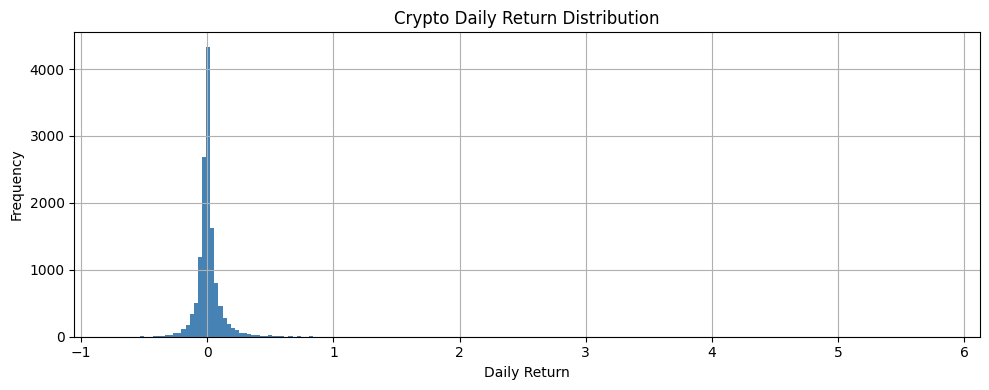

In [27]:
# Daily returns distribution

crypto_df["Daily_Return"] = crypto_df.groupby("Ticker")["Close"].transform(
    lambda x: x.pct_change()
)

plt.figure(figsize=(10, 4))
crypto_df["Daily_Return"].hist(bins=200, edgecolor="none", color="steelblue")
plt.title("Crypto Daily Return Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


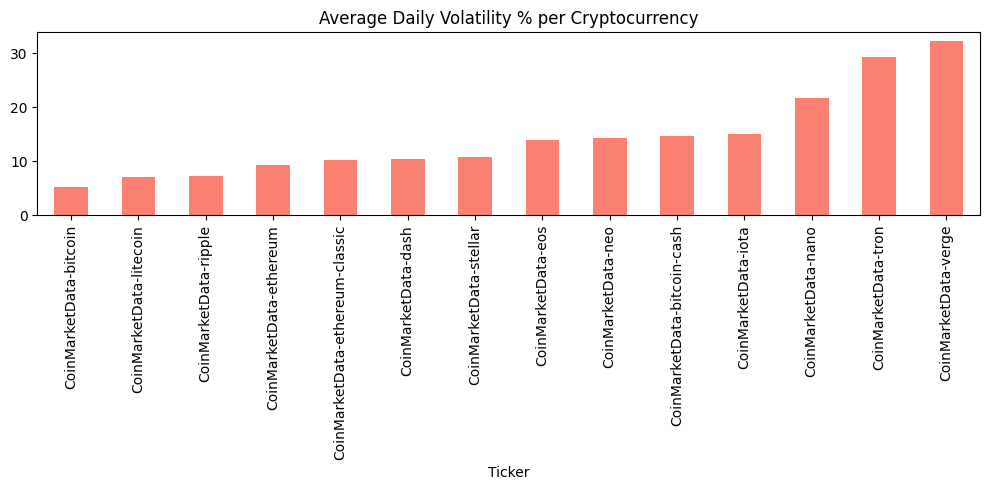

In [28]:
# Volatility per coin

crypto_df["Volatility_pct"] = (
    (crypto_df["High"] - crypto_df["Low"]) / crypto_df["Close"] * 100
)
plt.figure(figsize=(10, 5))
crypto_df.groupby("Ticker")["Volatility_pct"].mean().sort_values().plot(
    kind="bar", color="salmon", edgecolor="none"
)
plt.title("Average Daily Volatility % per Cryptocurrency")
plt.tight_layout()
plt.show()


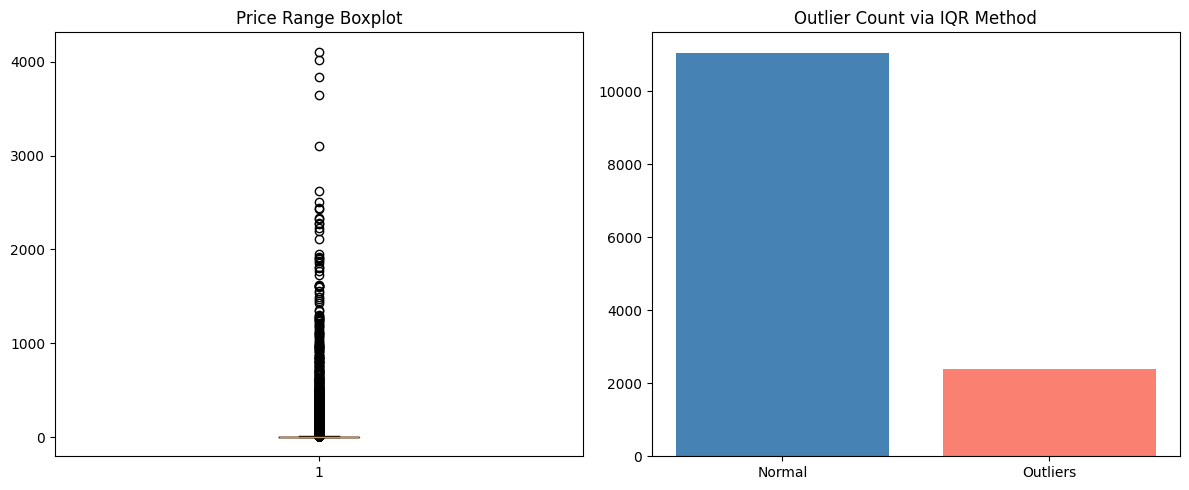

Outliers : 2,399  (17.83%)


In [29]:
# Price range outlier analysis

crypto_df["price_range"] = crypto_df["High"] - crypto_df["Low"]

Q1  = crypto_df["price_range"].quantile(0.25)
Q3  = crypto_df["price_range"].quantile(0.75)
IQR = Q3 - Q1
outliers = crypto_df[
    (crypto_df["price_range"] < Q1 - 1.5 * IQR) |
    (crypto_df["price_range"] > Q3 + 1.5 * IQR)
]
normal_count = len(crypto_df) - len(outliers)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot(crypto_df["price_range"].dropna())
axes[0].set_title("Price Range Boxplot")

axes[1].bar(["Normal", "Outliers"], [normal_count, len(outliers)], color=["steelblue", "salmon"])
axes[1].set_title("Outlier Count via IQR Method")

plt.tight_layout()
plt.show()
print(f"Outliers : {len(outliers):,}  ({len(outliers) / len(crypto_df) * 100:.2f}%)")


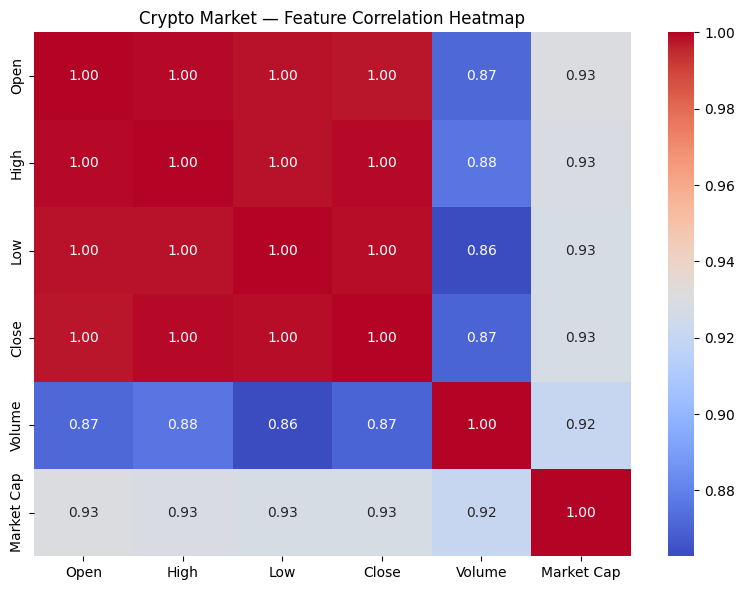

In [30]:
# OHLCV + Market Cap correlation heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(
    crypto_df[["Open", "High", "Low", "Close", "Volume", "Market Cap"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm"
)
plt.title("Crypto Market — Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


---
## Step 4 — Feature Engineering

### Technical Indicator Helper Functions

Three standard financial indicators are defined here and reused across all datasets:

| Function | Indicator | Window |
|---|---|---|
| `calc_rsi` | Relative Strength Index | 14 periods |
| `calc_macd` | MACD Line, Signal, Histogram | 12/26/9 |
| `calc_atr` | Average True Range | 14 periods |


In [31]:
def calc_rsi(data: pd.DataFrame, window: int = 14) -> pd.Series:
    delta    = data["Close"].diff()
    gain     = delta.where(delta > 0, 0.0).fillna(0)
    loss     = (-delta.where(delta < 0, 0.0)).fillna(0)
    avg_gain = gain.ewm(com=window - 1, min_periods=window).mean()
    avg_loss = loss.ewm(com=window - 1, min_periods=window).mean()
    rs       = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))


def calc_macd(series: pd.Series, fast=12, slow=26, signal=9):
    ema_fast = series.ewm(span=fast, adjust=False).mean()
    ema_slow = series.ewm(span=slow, adjust=False).mean()

    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    histogram = macd_line - signal_line

    return macd_line, signal_line, histogram


def calc_atr(high: pd.Series, low: pd.Series, close: pd.Series, window=14):
    tr1 = high - low
    tr2 = (high - close.shift(1)).abs()
    tr3 = (low - close.shift(1)).abs()

    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = tr.rolling(window=window).mean()

    return atr


print("Technical indicator helpers defined: calc_rsi, calc_macd, calc_atr")


Technical indicator helpers defined: calc_rsi, calc_macd, calc_atr


### Part A — Yahoo Finance: Feature Engineering

**Features added:**

| Feature | Description |
|---|---|
| `MA_5`, `MA_10` | Simple moving averages |
| `Daily_Return` | Day-over-day percentage change |
| `rolling_mean_7`, `rolling_std_7` | 7-day rolling mean / std |
| `RSI_14` | 14-period RSI |
| `MACD_Line`, `MACD_Signal`, `MACD_Hist` | MACD components |
| `ATR` | Average True Range |
| `lag_1`, `lag_2` | Lagged closing prices |
| `Volatility_10` | 10-day rolling return std |
| `target_price` | Next-day return (regression target) |


In [32]:
# Sort chronologically before computing rolling / lag features
yahoo_data = yahoo_data.sort_values("Date").reset_index(drop=True)


In [33]:
# Moving averages
yahoo_data["MA_5"]  = yahoo_data["Close"].rolling(window=5).mean()
yahoo_data["MA_10"] = yahoo_data["Close"].rolling(window=10).mean()


In [34]:
# Daily return and rolling statistics
yahoo_data["Daily_Return"]   = yahoo_data["Close"].pct_change()
yahoo_data["rolling_mean_7"] = yahoo_data["Close"].rolling(7).mean()
yahoo_data["rolling_std_7"]  = yahoo_data["Close"].rolling(7).std()


In [35]:
# Technical indicators
yahoo_data["RSI_14"] = calc_rsi(yahoo_data)

yahoo_data["MACD_Line"], yahoo_data["MACD_Signal"], yahoo_data["MACD_Hist"] = (
    calc_macd(yahoo_data["Close"])
)

yahoo_data["ATR"] = calc_atr(yahoo_data["High"], yahoo_data["Low"], yahoo_data["Close"])


In [36]:
# Lag features and volatility
yahoo_data["lag_1"]        = yahoo_data["Close"].shift(1)
yahoo_data["lag_2"]        = yahoo_data["Close"].shift(2)
yahoo_data["Volatility_10"] = yahoo_data["Daily_Return"].rolling(window=10).std()


In [37]:
# Regression target: next-day return
yahoo_data["target_price"] = yahoo_data["Close"].pct_change().shift(-1)

# Drop rows with NaN introduced by rolling / shift operations
yahoo_data = yahoo_data.dropna().reset_index(drop=True)
print(f"Yahoo Finance after feature engineering — shape : {yahoo_data.shape}")


Yahoo Finance after feature engineering — shape : (4208032, 24)


### Part B — Credit Card Fraud: Feature Engineering

**Processing steps:**
- Remove duplicate transactions
- Engineer time-based features (`Hour_of_Day`, `Is_Night`, `Time_Since_Last`)
- Log-transform `Amount` to reduce skewness

> **Class imbalance note:** The dataset is heavily skewed (~284k legitimate vs ~492 fraud). Rather than over/under-sampling, `class_weight='balanced'` is applied inside all classifiers.


In [38]:
# Remove duplicates
fraud_data = fraud_data.drop_duplicates().reset_index(drop=True)
print(f"After removing duplicates — shape : {fraud_data.shape}")


After removing duplicates — shape : (283726, 31)


In [39]:
# Time-based features
seconds_per_day = 86_400
fraud_data["Hour_of_Day"]     = (fraud_data["Time"] % seconds_per_day) // 3600
fraud_data["Is_Night"]        = (
    (fraud_data["Hour_of_Day"] >= 22) | (fraud_data["Hour_of_Day"] <= 5)
).astype(int)
fraud_data["Time_Since_Last"] = fraud_data["Time"].diff().fillna(0)


In [40]:
# Log-transform Amount
fraud_data["Amount_Log"] = np.log1p(fraud_data["Amount"])

dist = fraud_data["Class"].value_counts()
print(f"Class distribution:\n{dist.to_string()}")
print(f"\nImbalance ratio : {dist[0] / dist[1]:.0f}:1")
print("\nNote: class_weight='balanced' will be used in all fraud classifiers.")


Class distribution:
Class
0    283253
1       473

Imbalance ratio : 599:1

Note: class_weight='balanced' will be used in all fraud classifiers.



### Part C — Crypto Market: Feature Engineering

**Features added:**

| Feature Group | Features |
|---|---|
| Moving Averages | `MA_7`, `MA_30`, `EMA_7`, `EMA_30` + ratio to Close |
| Volatility | `Volatility_7`, `Volatility_30`, `Price_Range_Pct` |
| Technical Indicators | `RSI`, `MACD_Line`, `MACD_Signal`, `MACD_Hist`, `ATR` |
| Lag Returns | `Return_Lag1` – `Return_Lag5` |
| Target | `Target_Return` — next-day log return |

All rolling/lag calculations are performed **per-ticker** using `groupby` to avoid look-ahead across different coins.


In [41]:
# Work on a clean copy; keep the raw EDA DataFrame intact
crypto_df_model = crypto_df.copy().sort_values(["Ticker", "Date"]).reset_index(drop=True)
print(f"Coins  : {crypto_df_model['Ticker'].nunique()}")
print(f"Shape  : {crypto_df_model.shape}")


Coins  : 14
Shape  : (13453, 11)


In [42]:
# Moving averages & EMA (per-ticker)
for span, label in [(7, "MA_7"), (30, "MA_30")]:
    crypto_df_model[label] = crypto_df_model.groupby("Ticker")["Close"].transform(
        lambda x, s=span: x.rolling(s).mean()
    )
for span, label in [(7, "EMA_7"), (30, "EMA_30")]:
    crypto_df_model[label] = crypto_df_model.groupby("Ticker")["Close"].transform(
        lambda x, s=span: x.ewm(span=s, adjust=False).mean()
    )

# MA / EMA ratios to Close
for col in ["MA_7", "MA_30", "EMA_7", "EMA_30"]:
    crypto_df_model[f"{col}_Ratio"] = crypto_df_model[col] / crypto_df_model["Close"]


In [43]:
# Volatility features
crypto_df_model["Daily_Return"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.pct_change()
)
crypto_df_model["Volatility_7"] = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(
    lambda x: x.rolling(7).std()
)
crypto_df_model["Volatility_30"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.pct_change().rolling(30).std()
)
crypto_df_model["Price_Range_Pct"] = (
    (crypto_df_model["High"] - crypto_df_model["Low"]) / crypto_df_model["Close"] * 100
)


In [44]:
# Volume momentum
crypto_df_model["Volume_Pct"] = crypto_df_model.groupby("Ticker")["Volume"].transform(
    lambda x: x.pct_change()
)

# Log Market Cap
crypto_df_model["Market_Cap_Log"] = np.log1p(crypto_df_model["Market Cap"])


In [45]:
# Lag return features
for lag in [1, 2, 3, 5]:
    crypto_df_model[f"Return_Lag{lag}"] = crypto_df_model.groupby("Ticker")["Daily_Return"].transform(
        lambda x, l=lag: x.shift(l)
    )


In [46]:
# RSI (per-ticker)
crypto_df_model["RSI"] = crypto_df_model.groupby("Ticker", group_keys=False).apply(
    lambda g: calc_rsi(g)
)


In [47]:
# MACD (per-ticker)
crypto_df_model["MACD_Line"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: x.ewm(span=12, adjust=False).mean() - x.ewm(span=26, adjust=False).mean()
)
crypto_df_model["MACD_Signal"] = crypto_df_model.groupby("Ticker")["MACD_Line"].transform(
    lambda x: x.ewm(span=9, adjust=False).mean()
)
crypto_df_model["MACD_Hist"] = crypto_df_model["MACD_Line"] - crypto_df_model["MACD_Signal"]


In [48]:
# ATR (per-ticker)
def _calc_atr_group(g: pd.DataFrame, window: int = 14) -> pd.Series:
    tr = pd.concat(
        [
            g["High"] - g["Low"],
            (g["High"] - g["Close"].shift(1)).abs(),
            (g["Low"]  - g["Close"].shift(1)).abs(),
        ],
        axis=1,
    ).max(axis=1)
    return tr.rolling(window).mean()

crypto_df_model["ATR"] = crypto_df_model.groupby("Ticker", group_keys=False).apply(
    _calc_atr_group
)


In [49]:
# Regression target: next-day log return (per-ticker)
crypto_df_model["Target_Return"] = crypto_df_model.groupby("Ticker")["Close"].transform(
    lambda x: np.log(x.shift(-1) / x)
)

crypto_df_model.dropna(inplace=True)
crypto_df_model.reset_index(drop=True, inplace=True)

print(f"After feature engineering — shape : {crypto_df_model.shape}")
print(f"Coins remaining : {crypto_df_model['Ticker'].nunique()}")
print(f"\nTarget_Return stats:\n{crypto_df_model['Target_Return'].describe()}")


After feature engineering — shape : (12464, 34)
Coins remaining : 14

Target_Return stats:
count    12464.000000
mean         0.004906
std          0.096202
min         -0.693147
25%         -0.028213
50%          0.000000
75%          0.030440
max          1.916923
Name: Target_Return, dtype: float64


---
## Step 5 — Train / Test Split & Feature Scaling

Each dataset uses a split strategy appropriate to its task:

| Dataset | Split Strategy | Reason |
|---|---|---|
| Yahoo Finance | Chronological (no shuffle) | Time-series — no future leakage |
| Credit Card Fraud | Stratified random | Preserves class imbalance |
| Crypto Market | TimeSeriesSplit (5 folds) | Multi-ticker time-series |

Scalers are **fit on training data only** and applied to both train and test sets.


### Part A — Yahoo Finance


In [50]:
YAHOO_FEATURES = [
    "Close", "Volume",
    "MA_5", "MA_10",
    "Daily_Return",
    "RSI_14", "MACD_Line", "MACD_Signal", "MACD_Hist",
    "lag_1", "lag_2",
    "Volatility_10",
]

X_yahoo = yahoo_data[YAHOO_FEATURES]
y_yahoo = yahoo_data["target_price"]

X_yahoo_train, X_yahoo_test, y_yahoo_train, y_yahoo_test = train_test_split(
    X_yahoo, y_yahoo,
    test_size=0.2,
    shuffle=False,          # chronological split
)

print(f"Train : X={X_yahoo_train.shape}, y={y_yahoo_train.shape}")
print(f"Test  : X={X_yahoo_test.shape},  y={y_yahoo_test.shape}")


Train : X=(3366425, 12), y=(3366425,)
Test  : X=(841607, 12),  y=(841607,)


In [51]:
scaler_yahoo = StandardScaler()
X_yahoo_train_scaled = scaler_yahoo.fit_transform(X_yahoo_train)
X_yahoo_test_scaled  = scaler_yahoo.transform(X_yahoo_test)

print("Yahoo Finance scaling complete.")


Yahoo Finance scaling complete.


### Part B — Credit Card Fraud


In [52]:
X_fraud = fraud_data.drop(columns=["Class", "Time", "Amount"])
y_fraud = fraud_data["Class"]

X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud,           # preserve class ratio
)

print(f"Train : X={X_fraud_train.shape}, y={y_fraud_train.shape}")
print(f"Test  : X={X_fraud_test.shape},  y={y_fraud_test.shape}")


Train : X=(226980, 32), y=(226980,)
Test  : X=(56746, 32),  y=(56746,)


In [53]:
scaler_fraud = StandardScaler()
X_fraud_train_scaled = scaler_fraud.fit_transform(X_fraud_train)
X_fraud_test_scaled  = scaler_fraud.transform(X_fraud_test)

print("Fraud scaling complete.")


Fraud scaling complete.


### Part C — Crypto Market


In [54]:
le = LabelEncoder()
crypto_df_model["Ticker_Encoded"] = le.fit_transform(crypto_df_model["Ticker"])

# Columns to exclude from the feature matrix
NON_FEATURE_COLS = [
    "Target_Return", "Ticker", "Date", "Year",
    "Volatility_pct", "price_range", "Daily_Return",
    "Open", "High", "Low", "Close", "Market Cap",
]

X_crypto = (
    crypto_df_model
    .drop(columns=NON_FEATURE_COLS, errors="ignore")
    .select_dtypes(include=["float64", "int64", "int32"])
)
y_crypto = crypto_df_model["Target_Return"]

print(f"Feature matrix shape : {X_crypto.shape}")
print(f"Target shape         : {y_crypto.shape}")


Feature matrix shape : (12464, 24)
Target shape         : (12464,)


In [55]:
# Sort globally by Date before TimeSeriesSplit
sort_idx = crypto_df_model["Date"].argsort().values
X_crypto = X_crypto.iloc[sort_idx]
y_crypto = y_crypto.iloc[sort_idx]

tscv = TimeSeriesSplit(n_splits=5)
for train_idx, test_idx in tscv.split(X_crypto):
    X_crypto_train, X_crypto_test = X_crypto.iloc[train_idx], X_crypto.iloc[test_idx]
    y_crypto_train, y_crypto_test = y_crypto.iloc[train_idx], y_crypto.iloc[test_idx]

print(f"Final fold — train : {X_crypto_train.shape}, test : {X_crypto_test.shape}")


Final fold — train : (10387, 24), test : (2077, 24)


In [56]:
scaler_crypto = StandardScaler()
X_crypto_train_scaled = scaler_crypto.fit_transform(X_crypto_train)
X_crypto_test_scaled  = scaler_crypto.transform(X_crypto_test)

print("Crypto scaling complete.")
print(f"Train scaled shape : {X_crypto_train_scaled.shape}")
print(f"Test  scaled shape : {X_crypto_test_scaled.shape}")


Crypto scaling complete.
Train scaled shape : (10387, 24)
Test  scaled shape : (2077, 24)


---
## Step 6 — Phase 1: Classical Machine Learning


### 6.1 — Naïve Bayes Classifier (Credit Card Fraud)

Gaussian Naïve Bayes provides a probabilistic baseline for the binary fraud classification task. It assumes feature independence and models each feature's likelihood as a Gaussian distribution.

Two variants are evaluated:
- **Baseline** — using all scaled features directly
- **PCA-reduced** — features compressed to 28 principal components (retaining ≈95 % variance)

In [57]:
#  Train Baseline Naïve Bayes 

nb_baseline = GaussianNB()
nb_baseline.fit(X_fraud_train_scaled, y_fraud_train)

y_pred_nb  = nb_baseline.predict(X_fraud_test_scaled)
y_prob_nb  = nb_baseline.predict_proba(X_fraud_test_scaled)[:, 1]


In [58]:
print("=== FINAL BASE MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred_nb):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred_nb, zero_division=0))

=== FINAL BASE MODEL EVALUATION ===
Accuracy: 0.9761

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.54     56746
weighted avg       1.00      0.98      0.99     56746



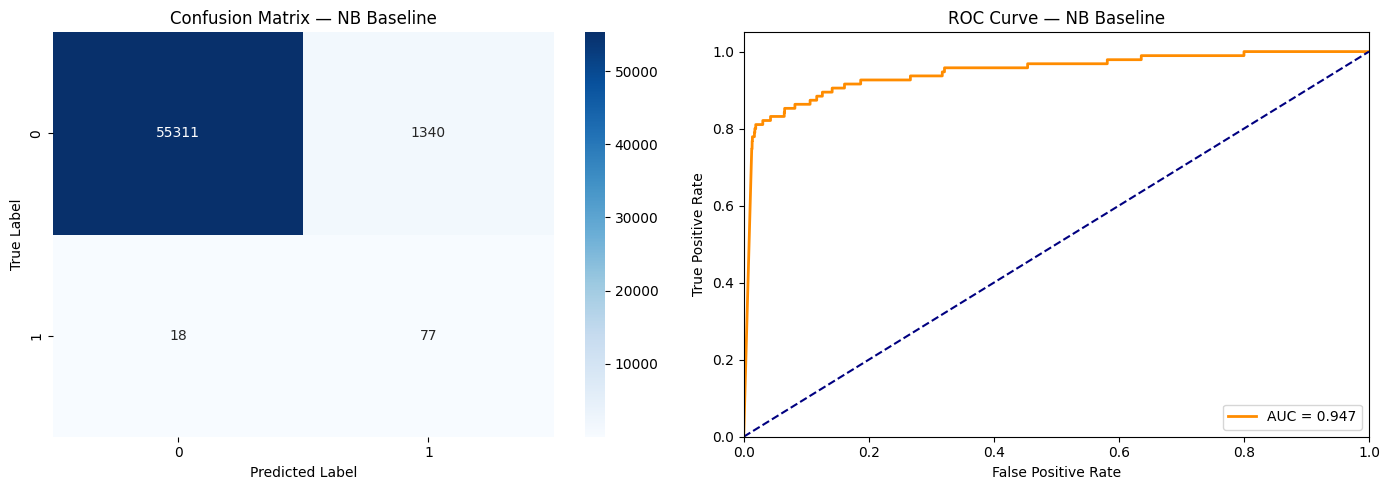

In [59]:
#  Confusion Matrix & ROC Curve — Baseline 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_nb = confusion_matrix(y_fraud_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix — NB Baseline")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# ROC Curve
fpr_nb, tpr_nb, _ = roc_curve(y_fraud_test, y_prob_nb)
roc_auc_nb = auc(fpr_nb, tpr_nb)
axes[1].plot(fpr_nb, tpr_nb, color="darkorange", lw=2, label=f"AUC = {roc_auc_nb:.3f}")
axes[1].plot([0, 1], [0, 1], "navy", lw=1.5, linestyle="--")
axes[1].set(xlim=[0, 1], ylim=[0, 1.05],
            xlabel="False Positive Rate", ylabel="True Positive Rate",
            title="ROC Curve — NB Baseline")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


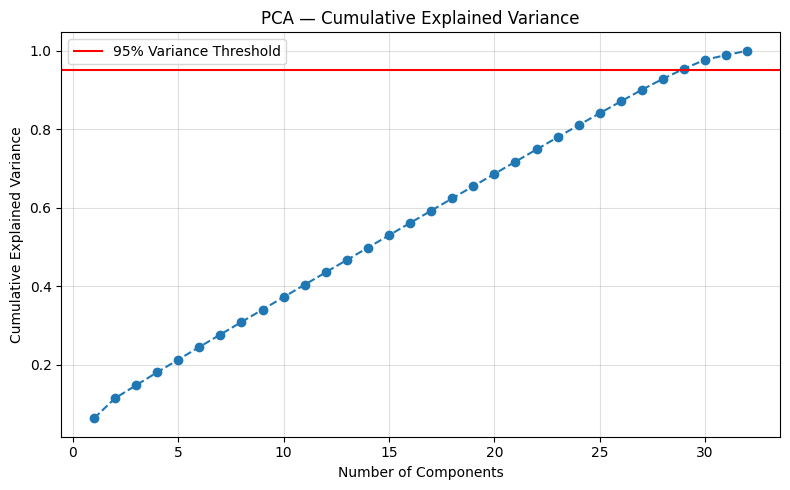

In [60]:
#  PCA Variance Analysis 

pca_analysis = PCA()
pca_analysis.fit(X_fraud_train_scaled)

cumulative_variance = np.cumsum(pca_analysis.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o", linestyle="--")
plt.axhline(y=0.95, color="red", linestyle="-", label="95% Variance Threshold")
plt.title("PCA — Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [61]:
#  Train PCA-Reduced Naïve Bayes 

pca_fraud = PCA(n_components=28)

X_fraud_train_pca = pca_fraud.fit_transform(X_fraud_train_scaled)
X_fraud_test_pca  = pca_fraud.transform(X_fraud_test_scaled)

print(f"Original features : {X_fraud_train_scaled.shape[1]}")
print(f"PCA components    : {X_fraud_train_pca.shape[1]}")

Original features : 32
PCA components    : 28


In [62]:
nb_pca = GaussianNB()
nb_pca.fit(X_fraud_train_pca, y_fraud_train)

y_pred_nb_pca = nb_pca.predict(X_fraud_test_pca)
y_prob_nb_pca = nb_pca.predict_proba(X_fraud_test_pca)[:, 1]

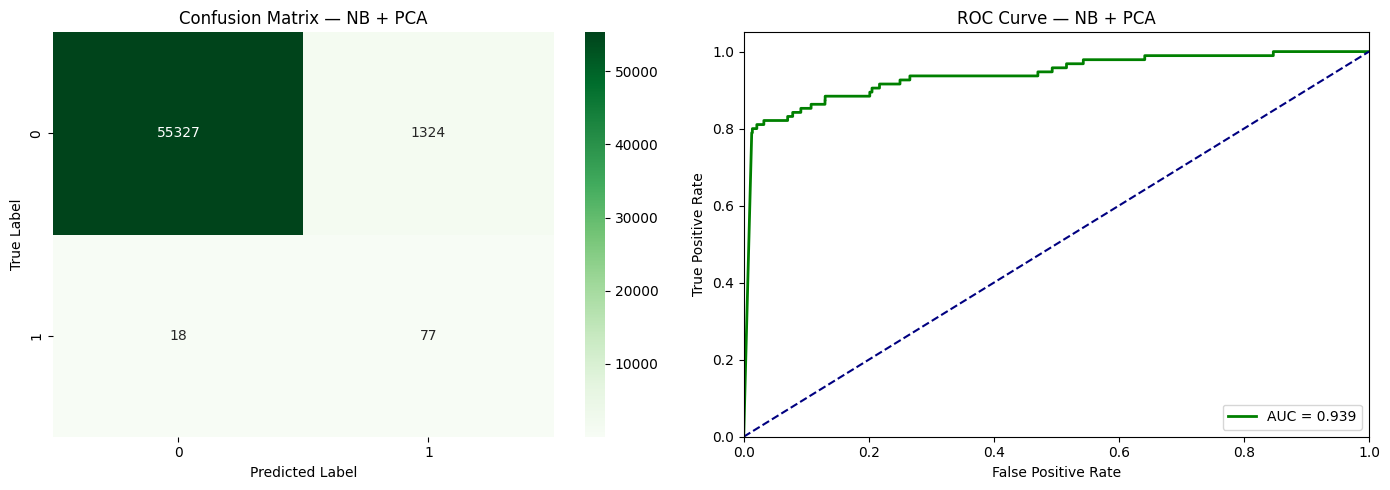

In [63]:
#  Confusion Matrix & ROC Curve — PCA Model 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_pca = confusion_matrix(y_fraud_test, y_pred_nb_pca)
sns.heatmap(cm_pca, annot=True, fmt="d", cmap="Greens", ax=axes[0])
axes[0].set_title("Confusion Matrix — NB + PCA")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

fpr_pca, tpr_pca, _ = roc_curve(y_fraud_test, y_prob_nb_pca)
roc_auc_pca = auc(fpr_pca, tpr_pca)
axes[1].plot(fpr_pca, tpr_pca, color="green", lw=2, label=f"AUC = {roc_auc_pca:.3f}")
axes[1].plot([0, 1], [0, 1], "navy", lw=1.5, linestyle="--")
axes[1].set(xlim=[0, 1], ylim=[0, 1.05],
            xlabel="False Positive Rate", ylabel="True Positive Rate",
            title="ROC Curve — NB + PCA")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


In [64]:
#  Model Comparison Summary 

print("=== Naïve Bayes Comparison ===")
print(f"{'Metric':<20} {'Baseline':>12} {'PCA-Reduced':>14}")
print("-" * 48)
print(f"{'ROC-AUC':<20} {roc_auc_nb:>12.4f} {roc_auc_pca:>14.4f}")
print(f"{'Accuracy':<20} {accuracy_score(y_fraud_test, y_pred_nb):>12.4f} "
      f"{accuracy_score(y_fraud_test, y_pred_nb_pca):>14.4f}")


=== Naïve Bayes Comparison ===
Metric                   Baseline    PCA-Reduced
------------------------------------------------
ROC-AUC                    0.9468         0.9389
Accuracy                   0.9761         0.9764


### 6.2 — KNN Regressor (Crypto Market)

K-Nearest Neighbours regression is applied to predict next-day log returns for the crypto market. Two variants are compared:

- **KNN (no PCA)** — trained on all scaled features
- **KNN + PCA** — features compressed to 95% variance before fitting


In [65]:
#  Train KNN on Full Scaled Features 

knn = KNeighborsRegressor(n_neighbors=10, p=2, weights="distance")
knn.fit(X_crypto_train_scaled, y_crypto_train)

y_crypto_test_pred = knn.predict(X_crypto_test_scaled)

In [66]:
test_r2  = r2_score(y_crypto_test, y_crypto_test_pred)
test_mae = mean_absolute_error(y_crypto_test, y_crypto_test_pred)
test_mse = mean_squared_error(y_crypto_test, y_crypto_test_pred)

print("=== KNN on scaled features (no PCA) ===")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE:      {test_mae:.6f}")
print(f"MSE:      {test_mse:.6f}")


=== KNN on scaled features (no PCA) ===
R2 Score: -0.0750
MAE:      0.076771
MSE:      0.012398


In [67]:
#  PCA Compression for Crypto 

pca_crypto = PCA(n_components=0.95)
X_crypto_train_pca = pca_crypto.fit_transform(X_crypto_train_scaled)
X_crypto_test_pca  = pca_crypto.transform(X_crypto_test_scaled)

print(f"PCA: {X_crypto_train_scaled.shape[1]} features → {X_crypto_train_pca.shape[1]} components (95% variance)")


PCA: 24 features → 13 components (95% variance)


In [68]:
# Train KNN 

knn_pca = KNeighborsRegressor(n_neighbors=40, p=1)
knn_pca.fit(X_crypto_train_pca, y_crypto_train)

y_crypto_test_pred_pca = knn_pca.predict(X_crypto_test_pca)

In [69]:
test_r2_pca  = r2_score(y_crypto_test, y_crypto_test_pred_pca)
test_mae_pca = mean_absolute_error(y_crypto_test, y_crypto_test_pred_pca)
test_mse_pca = mean_squared_error(y_crypto_test, y_crypto_test_pred_pca)

print("=== KNN + PCA on scaled features ===")
print(f"R2 Score: {test_r2_pca:.4f}")
print(f"MAE:      {test_mae_pca:.6f}")
print(f"MSE:      {test_mse_pca:.6f}")


=== KNN + PCA on scaled features ===
R2 Score: 0.0195
MAE:      0.072854
MSE:      0.011308


In [70]:
#  KNN Comparison Summary 

print("=== KNN Comparison ===")
print(f"{'Metric':<8} {'Full Features':>16} {'PCA-Reduced':>14}")
print("-" * 42)

print(f"{'R²':<8} {test_r2:>16.4f} "
      f"{test_r2_pca:>14.4f}")

print(f"{'MAE':<8} {test_mae:>16.6f} "
      f"{test_mae_pca:>14.6f}")

print(f"{'MSE':<8} {test_mse:>16.6f} "
      f"{test_mse_pca:>14.6f}")


=== KNN Comparison ===
Metric      Full Features    PCA-Reduced
------------------------------------------
R²                -0.0750         0.0195
MAE              0.076771       0.072854
MSE              0.012398       0.011308


### 6.3 — Ensemble Regressors with Optuna Tuning (Yahoo Finance)

Random Forest and XGBoost regressors are tuned with **Optuna** (Bayesian optimisation) to minimise MSE on next-day stock returns.

Each model runs an independent Optuna study with `n_trials=50`. The best parameters are then used to train and evaluate the final model.


In [71]:
print("Initializing Final Models with Explicit Best Parameters...")
sample_ticker = yahoo_data['Ticker'].iloc[0]
stock_df = yahoo_data[yahoo_data['Ticker'] == sample_ticker].copy()

features = ['Open', 'High', 'Low', 'Close', 'Volume', 'MA_5', 'MA_10', 'Daily_Return']
X_stock = stock_df[features]
y_stock = stock_df['target_price']

X_stock_train, X_stock_test, y_stock_train, y_stock_test = train_test_split(
    X_stock, y_stock,
    test_size=0.2,
    shuffle=False
)
# 1. Setup Final Random Forest (From Optuna Trial 58)
best_params_rf = {
    'n_estimators': 210,
    'max_depth': 5,
    'min_samples_split': 2,
    'min_samples_leaf': 10,
    'random_state': 42,
    'n_jobs': -1
}
final_rf = RandomForestRegressor(**best_params_rf)

print("Training Final Random Forest...")
final_rf.fit(X_stock_train, y_stock_train)
rf_predictions = final_rf.predict(X_stock_test)


Initializing Final Models with Explicit Best Parameters...
Training Final Random Forest...


In [72]:
# 2. Setup Final XGBoost (From Optuna Trial 11)
best_params_xgb = {
    'n_estimators': 380,
    'learning_rate': 0.27926006434202694,
    'max_depth': 6,
    'subsample': 0.5218003352159574,
    'colsample_bytree': 0.7341882687722235,
    'min_child_weight': 1,
    'gamma': 1.0703765890972565,
    'reg_alpha': 0.016006678280215965,
    'reg_lambda': 8.214406800943035,
    'objective': 'reg:squarederror',
    'random_state': 42,
    'tree_method': 'hist',
    'device': 'cuda'
}
final_xgb = XGBRegressor(**best_params_xgb)

print("Training Final XGBoost...")
final_xgb.fit(X_stock_train, y_stock_train)
xgb_predictions = final_xgb.predict(X_stock_test)

Training Final XGBoost...


In [73]:
# 3. Print Evaluation Metrics
print("\n--- Final Model Evaluation (Out-of-Sample) ---")
print("RANDOM FOREST:")
print(f"  MSE: {mean_squared_error(y_stock_test, rf_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, rf_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, rf_predictions):.4f}")

print("\nXGBOOST:")
print(f"  MSE: {mean_squared_error(y_stock_test, xgb_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, xgb_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, xgb_predictions):.4f}")


--- Final Model Evaluation (Out-of-Sample) ---
RANDOM FOREST:
  MSE: 2.213727
  MAE: 0.596070
  R2:  -0.1251

XGBOOST:
  MSE: 2.330425
  MAE: 0.795760
  R2:  -0.1844


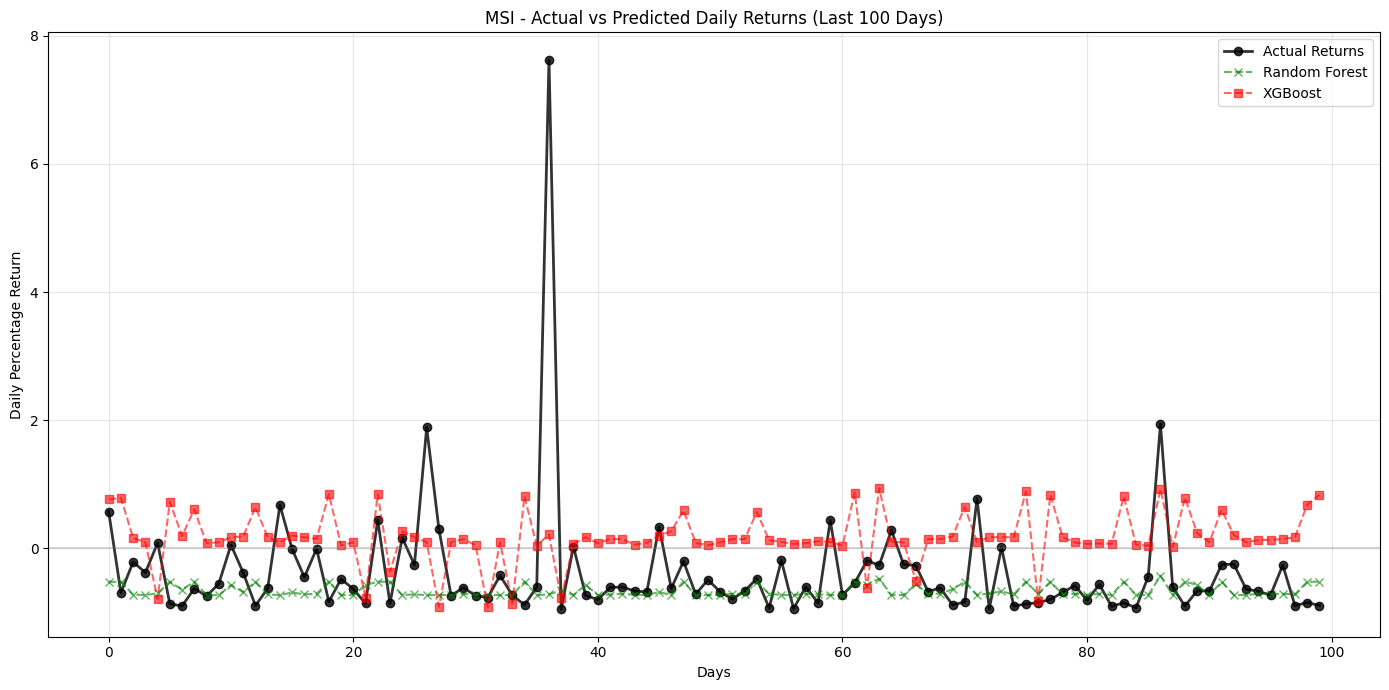

In [74]:
# 4. Plotting Actuals vs Both Models
plt.figure(figsize=(14, 7))
days_to_plot = 100

plt.plot(y_stock_test.values[-days_to_plot:], label='Actual Returns', color='black', marker='o', alpha=0.8, linewidth=2)
plt.plot(rf_predictions[-days_to_plot:], label='Random Forest', color='green', marker='x', alpha=0.6, linestyle='--')
plt.plot(xgb_predictions[-days_to_plot:], label='XGBoost', color='red', marker='s', alpha=0.6, linestyle='--')

try:
    ticker_name = sample_ticker
except NameError:
    ticker_name = "Stock"

plt.title(f"{ticker_name} - Actual vs Predicted Daily Returns (Last 100 Days)")
plt.xlabel("Days")
plt.ylabel("Daily Percentage Return")
plt.axhline(0, color='gray', linestyle='-', alpha=0.3)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 7 — Phase 2: Deep Learning

---
### 7.1 — 1D-CNN for Stock Return Prediction (Yahoo Finance)

A 1D Convolutional Neural Network processes the tabular feature matrix as a one-step sequence (each row treated as a single time step). Multiple architectural variants are explored to select the best configuration.

**Helper:** `plot_training_history` visualises train/validation loss and MAE across epochs.


In [75]:
def plot_training_history(history: tf.keras.callbacks.History, title: str = "") -> None:
    """Plot loss and MAE curves for a Keras training history."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history["loss"],     label="Train Loss")
    ax1.plot(history.history["val_loss"], label="Val Loss")
    ax1.set_title(f"Loss  {title}")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True, alpha=0.4)

    ax2.plot(history.history["mae"],     label="Train MAE")
    ax2.plot(history.history["val_mae"], label="Val MAE")
    ax2.set_title(f"MAE  {title}")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Error")
    ax2.legend()
    ax2.grid(True, alpha=0.4)

    plt.tight_layout()
    plt.show()


In [76]:
#  Build Model 

yahoo_cnn1 = models.Sequential([
    layers.Conv1D(32,8, activation='leaky_relu', padding='same', input_shape=(12,1)),
    layers.BatchNormalization(),

    layers.Conv1D(64,8, strides=2,activation='softplus', padding='same'),
    layers.MaxPooling1D(pool_size = 2),

    layers.Conv1D(64,8, activation='relu', padding='same'),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(32, activation='leaky_relu'),
    layers.Dense(1,  activation='leaky_relu'),

])

I0000 00:00:1776702614.346774      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15479 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [77]:
#  Compile Model 

yahoo_cnn1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=0.001,
        decay_steps=10000,
        decay_rate=0.9)),
    loss='huber',
    metrics=['mae'],
)

In [78]:
#  Trian 

yahoo_cnn1_history = yahoo_cnn1.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)

Epoch 1/20


I0000 00:00:1776702619.399480      93 service.cc:152] XLA service 0x7b4bb402cc10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776702619.399525      93 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1776702619.929388      93 cuda_dnn.cc:529] Loaded cuDNN version 91002


  42/6576 ━━━━━━━━━━━━━━━━━━━━ 24s 4ms/step - loss: 1.8575 - mae: 2.2190

I0000 00:00:1776702622.931316      93 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


6576/6576 ━━━━━━━━━━━━━━━━━━━━ 38s 5ms/step - loss: 1.9136 - mae: 2.2580 - val_loss: 1.1781 - val_mae: 1.5161
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 1.8388 - mae: 2.1807 - val_loss: 1.1827 - val_mae: 1.5265
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8552 - mae: 2.1969 - val_loss: 1.1548 - val_mae: 1.4972
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8229 - mae: 2.1642 - val_loss: 1.1745 - val_mae: 1.5078
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8342 - mae: 2.1755 - val_loss: 1.1995 - val_mae: 1.5338
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8305 - mae: 2.1715 - val_loss: 1.2081 - val_mae: 1.5375
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.8177 - mae: 2.1587 - val_loss: 1.1891 - val_mae: 1.5267
Epoch 8/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.7809 - mae: 2.1220 - val_loss: 1.9698 - val_mae: 2.3021
Epoch 9/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 3

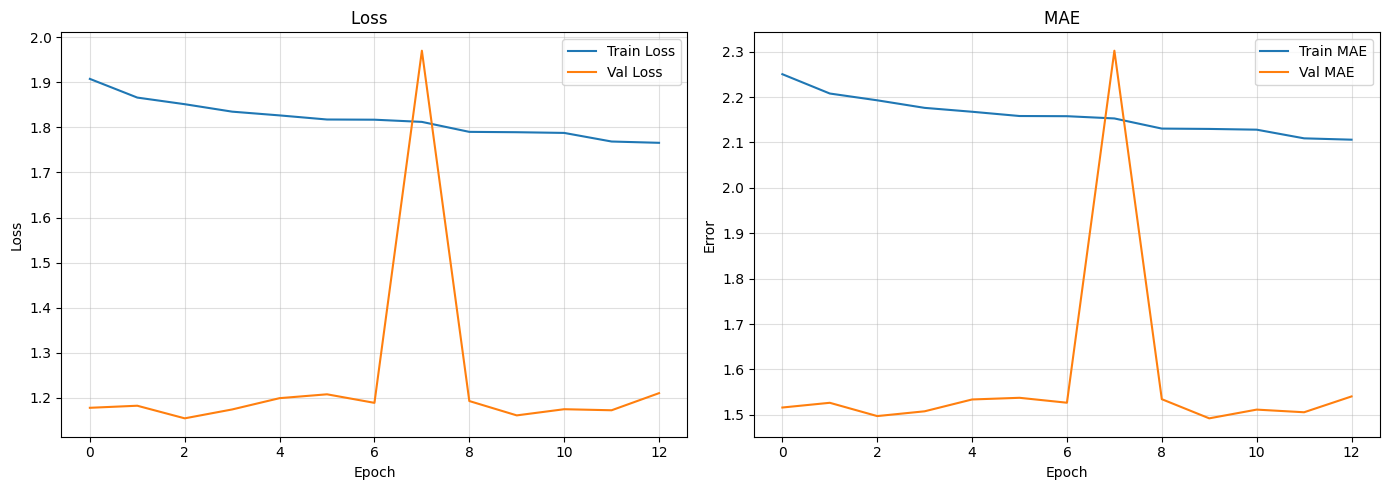

In [79]:
#  Evaluate 

plot_training_history(yahoo_cnn1_history)

#### Variant A — Leaky ReLU activations + ExponentialDecay (Adam)


In [80]:
#  Build Model 

cnn_yahoo_linear = models.Sequential([
        layers.Conv1D(32, 8, activation="leaky_relu", padding="same", input_shape=(X_yahoo_train_scaled.shape[1], 1)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, strides=2, activation="softplus", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [81]:
#  Compile 

cnn_yahoo_linear.compile(
    optimizer=keras.optimizers.Adam(learning_rate=keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=0.001,
        decay_steps=10000,
        decay_rate=0.9)),
    loss='huber',
    metrics=['mae'],
)
cnn_yahoo_linear.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 12, 32)         │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 6, 64)          │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 3, 64)          │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 3, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,161 (219.38 KB)

 Trainable params: 55,969 (218.63 KB)

 Non-trainable params: 192 (768.00 B)

In [82]:
#  Train 

history_linear = cnn_yahoo_linear.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 39s 5ms/step - loss: 1.9504 - mae: 2.2962 - val_loss: 1.2483 - val_mae: 1.5938
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8812 - mae: 2.2245 - val_loss: 1.1735 - val_mae: 1.5048
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8469 - mae: 2.1895 - val_loss: 1.1815 - val_mae: 1.5137
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.7959 - mae: 2.1380 - val_loss: 1.1773 - val_mae: 1.5106
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.7967 - mae: 2.1388 - val_loss: 1.1865 - val_mae: 1.5145
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8067 - mae: 2.1488 - val_loss: 1.1669 - val_mae: 1.4956
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8094 - mae: 2.1509 - val_loss: 1.1656 - val_mae: 1.5067
Epoch 8/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.7792 - mae: 2.1209 - val_loss: 1.1575 - val_mae: 1.4947
Epoch 9/20
6576/6576 ━━━━━━━━━━━

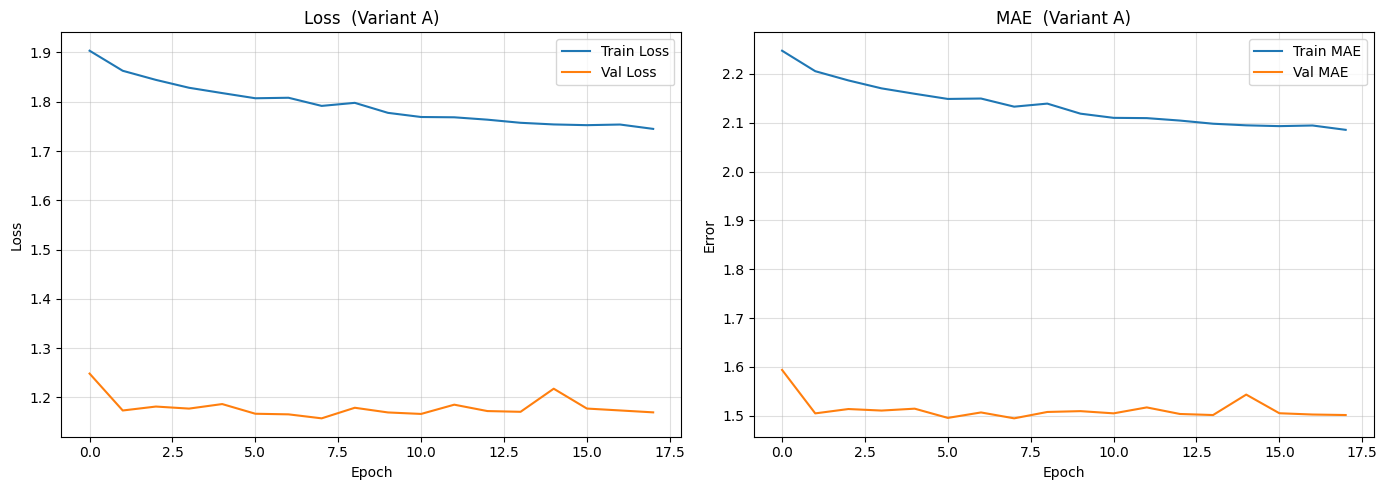

In [83]:
#  Evaluate 
plot_training_history(history_linear, title="(Variant A)")

In [84]:
y_pred_cnn_A = cnn_yahoo_linear.predict(X_yahoo_test_scaled).ravel()
print(f"Variant A — R²  : {r2_score(y_yahoo_test, y_pred_cnn_A):.4f}")
print(f"Variant A — MAE : {mean_absolute_error(y_yahoo_test, y_pred_cnn_A):.6f}")
print(f"Variant A — MSE : {mean_squared_error(y_yahoo_test, y_pred_cnn_A):.6f}")

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 47s 2ms/step
Variant A — R²  : 0.0803
Variant A — MAE : 1.494666
Variant A — MSE : 52.971213


#### Variant B — ReLU activations + AdamW weight decay


In [85]:
#  Build Model 

cnn_yahoo_linear2 = models.Sequential([
        layers.Conv1D(32, 8, activation="relu", padding="same", input_shape=(X_yahoo_train_scaled.shape[1], 1)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, strides=2, activation="softplus", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [86]:
#  Compile 

cnn_yahoo_linear2.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004),
    loss="huber",
    metrics=["mae"],
)


In [87]:
#  Train 

history_linear2 = cnn_yahoo_linear2.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 40s 5ms/step - loss: 1.9217 - mae: 2.2664 - val_loss: 1.1666 - val_mae: 1.5096
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - loss: 1.8374 - mae: 2.1797 - val_loss: 1.1537 - val_mae: 1.5048
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - loss: 1.8449 - mae: 2.1874 - val_loss: 1.1695 - val_mae: 1.5228
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - loss: 1.7983 - mae: 2.1408 - val_loss: 1.1628 - val_mae: 1.4974
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.7702 - mae: 2.1123 - val_loss: 1.1695 - val_mae: 1.5185
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - loss: 1.8395 - mae: 2.1817 - val_loss: 1.1941 - val_mae: 1.5212
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.8002 - mae: 2.1422 - val_loss: 1.1713 - val_mae: 1.4963
Epoch 8/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - loss: 1.7621 - mae: 2.1039 - val_loss: 1.2416 - val_mae: 1.5734
Epoch 9/20
6576/6576 ━━━━━━━━━━━

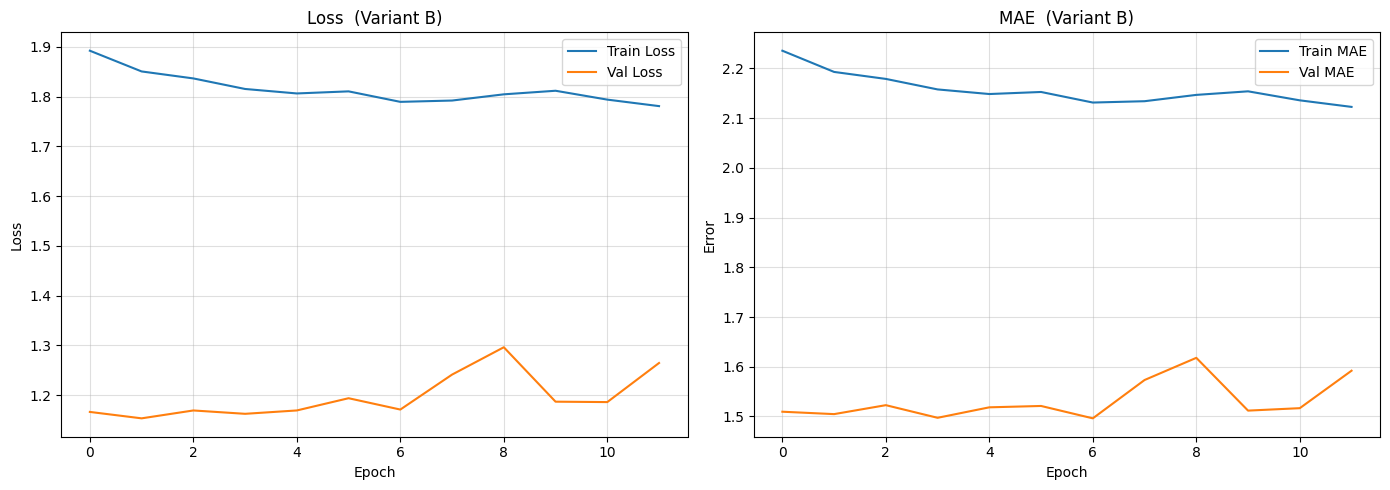

In [88]:
#  Evaluate 

plot_training_history(history_linear2, title="(Variant B)")

In [89]:
y_pred_cnn_B = cnn_yahoo_linear2.predict(X_yahoo_test_scaled).ravel()
print(f"Variant B — R²  : {r2_score(y_yahoo_test, y_pred_cnn_B):.4f}")
print(f"Variant B — MAE : {mean_absolute_error(y_yahoo_test, y_pred_cnn_B):.6f}")
print(f"Variant B — MSE : {mean_squared_error(y_yahoo_test, y_pred_cnn_B):.6f}")

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 48s 2ms/step
Variant B — R²  : 0.0739
Variant B — MAE : 1.504788
Variant B — MSE : 53.334763


#### Variant C — Deeper architecture + two MaxPooling layers


In [90]:
#  Build Model 

cnn_yahoo_linear3 = models.Sequential([
        layers.Conv1D(32, 8, activation="relu", padding="same",input_shape=(X_yahoo_train_scaled.shape[1], 1)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(32, 8, activation="leaky_relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [91]:
#  Compile 

cnn_yahoo_linear3.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004),
    loss="huber",
    metrics=["mae"],
)


In [92]:
#  Train 

history_linear3 = cnn_yahoo_linear3.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 46s 6ms/step - loss: 1.8742 - mae: 2.2199 - val_loss: 1.1678 - val_mae: 1.5135
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - loss: 1.8192 - mae: 2.1625 - val_loss: 1.2034 - val_mae: 1.5509
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - loss: 1.7968 - mae: 2.1396 - val_loss: 1.1733 - val_mae: 1.5051
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - loss: 1.7982 - mae: 2.1405 - val_loss: 1.1783 - val_mae: 1.5089
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - loss: 1.8280 - mae: 2.1709 - val_loss: 1.2284 - val_mae: 1.5655
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - loss: 1.8007 - mae: 2.1433 - val_loss: 1.1931 - val_mae: 1.5289
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - loss: 1.7994 - mae: 2.1419 - val_loss: 1.1901 - val_mae: 1.5273
Epoch 8/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 37s 6ms/step - loss: 1.8520 - mae: 2.1947 - val_loss: 1.1701 - val_mae: 1.5175
Epoch 9/20
6576/6576 ━━━━━━━━━━━

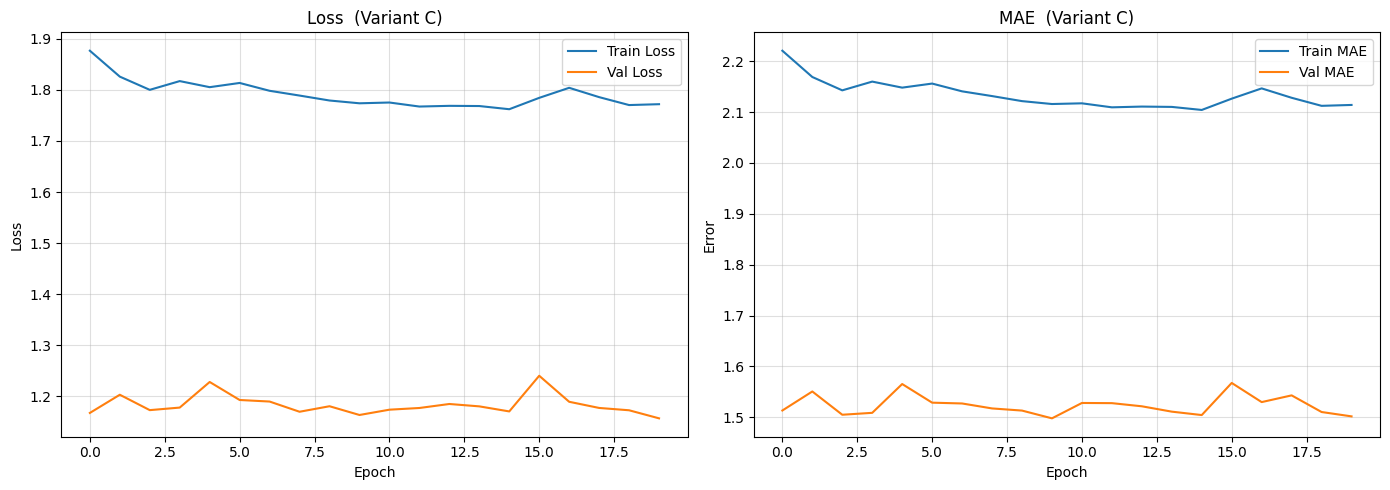

In [93]:
#  Evaluate 

plot_training_history(history_linear3, title="(Variant C)")

In [94]:
y_pred_cnn_C = cnn_yahoo_linear3.predict(X_yahoo_test_scaled).ravel()
print(f"Variant C — R²  : {r2_score(y_yahoo_test, y_pred_cnn_C):.4f}")
print(f"Variant C — MAE : {mean_absolute_error(y_yahoo_test, y_pred_cnn_C):.6f}")
print(f"Variant C — MSE : {mean_squared_error(y_yahoo_test, y_pred_cnn_C):.6f}")

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 49s 2ms/step
Variant C — R²  : 0.0854
Variant C — MAE : 1.501927
Variant C — MSE : 52.674772


#### Variant D — RMSprop + ExponentialDecay


In [95]:
#  Build Model 

cnn_yahoo_rms = models.Sequential([
        layers.Conv1D(32, 8, activation="relu", padding="same",input_shape=(X_yahoo_train_scaled.shape[1], 1)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, strides=2, activation="softplus", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [96]:
#  Compile 

cnn_yahoo_rms.compile(
    optimizer=tf.keras.optimizers.RMSprop(
        learning_rate=tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=0.001,
            decay_steps=10_000,
            decay_rate=0.9,
        ),
        rho=0.9,
    ),
    loss="huber",
    metrics=[
        "mae",
        tf.keras.metrics.RootMeanSquaredError(name="rmse"),
    ])


In [97]:
#  Train 

history_rms = cnn_yahoo_rms.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
     epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 38s 5ms/step - loss: 1.9532 - mae: 2.2990 - rmse: 43.1514 - val_loss: 1.1996 - val_mae: 1.5532 - val_rmse: 7.2828
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8458 - mae: 2.1879 - rmse: 44.0322 - val_loss: 1.1847 - val_mae: 1.5405 - val_rmse: 7.3182
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.8086 - mae: 2.1505 - rmse: 36.1012 - val_loss: 1.2417 - val_mae: 1.5715 - val_rmse: 7.3895
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - loss: 1.7891 - mae: 2.1307 - rmse: 35.8426 - val_loss: 1.2276 - val_mae: 1.5580 - val_rmse: 7.4436
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.7863 - mae: 2.1279 - rmse: 34.8706 - val_loss: 1.2331 - val_mae: 1.5781 - val_rmse: 7.3284
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1.7917 - mae: 2.1329 - rmse: 40.7839 - val_loss: 1.2830 - val_mae: 1.6121 - val_rmse: 7.9982
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1

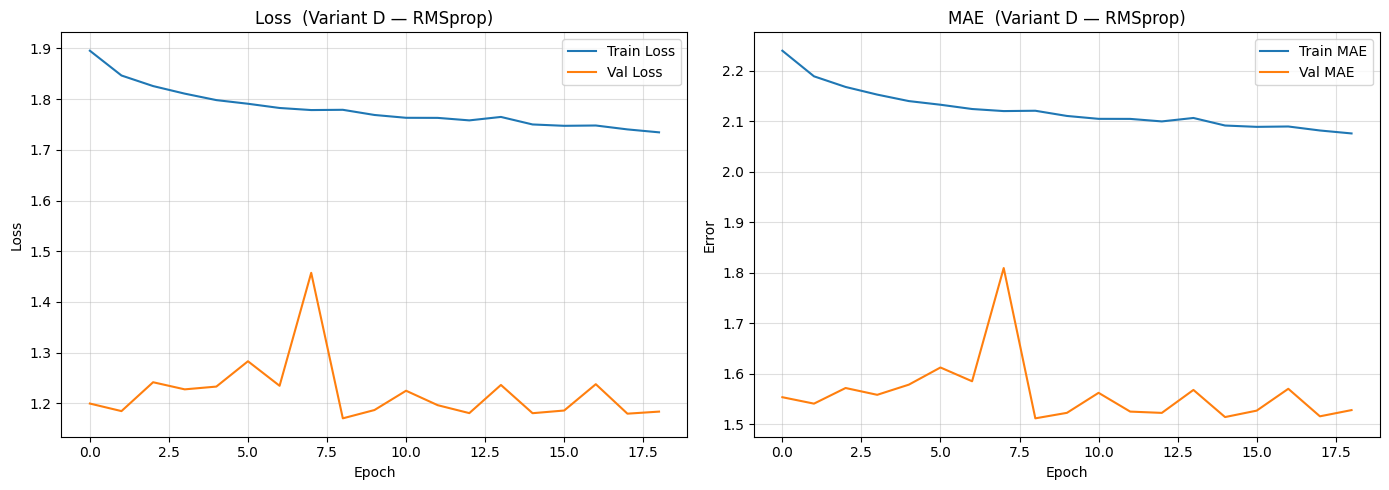

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 45s 2ms/step
Variant D — R²  : 0.0732
Variant D — MAE : 1.511409
Variant D — MSE : 53.380284


In [98]:
#  Evaluate 
plot_training_history(history_rms, title="(Variant D — RMSprop)")

y_pred_cnn_rms = cnn_yahoo_rms.predict(X_yahoo_test_scaled).ravel()
print(f"Variant D — R²  : {r2_score(y_yahoo_test, y_pred_cnn_rms):.4f}")
print(f"Variant D — MAE : {mean_absolute_error(y_yahoo_test, y_pred_cnn_rms):.6f}")
print(f"Variant D — MSE : {mean_squared_error(y_yahoo_test, y_pred_cnn_rms):.6f}")


#### Variant E — Lion Optimizer + ExponentialDecay


In [99]:
#  Build Model 

cnn_yahoo_lion = models.Sequential([
        layers.Conv1D(32, 8, activation="relu", padding="same",input_shape=(X_yahoo_train_scaled.shape[1], 1)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, strides=2, activation="softplus", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [100]:
#  Compile 
cnn_yahoo_lion.compile(
    optimizer=tf.keras.optimizers.Lion(
        learning_rate=tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=0.0001,
            decay_steps=10_000,
            decay_rate=0.9,
        ),
        weight_decay=0.01,
    ),
    loss="mse",
    metrics=[
        "mae",
        tf.keras.metrics.RootMeanSquaredError(name="rmse"),
    ],
)


In [101]:
#  Train 

history_lion = cnn_yahoo_lion.fit(
    X_yahoo_train_scaled, y_yahoo_train,
    validation_data=(X_yahoo_test_scaled, y_yahoo_test),
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 37s 5ms/step - loss: 1940.7516 - mae: 2.9471 - rmse: 42.4656 - val_loss: 55.2996 - val_mae: 1.9539 - val_rmse: 7.4364
Epoch 2/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - loss: 1273.0289 - mae: 2.9390 - rmse: 34.6066 - val_loss: 111.2005 - val_mae: 4.7534 - val_rmse: 10.5452
Epoch 3/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 2501.2029 - mae: 3.2946 - rmse: 49.1814 - val_loss: 79.1006 - val_mae: 3.1742 - val_rmse: 8.8939
Epoch 4/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 1238.4844 - mae: 3.1400 - rmse: 34.3524 - val_loss: 66.4180 - val_mae: 2.6969 - val_rmse: 8.1497
Epoch 5/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 1612.4688 - mae: 2.9924 - rmse: 38.7078 - val_loss: 57.7917 - val_mae: 2.2208 - val_rmse: 7.6021
Epoch 6/20
6576/6576 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - loss: 1777.5814 - mae: 3.2512 - rmse: 41.0046 - val_loss: 55.1441 - val_mae: 2.1819 - val_rmse: 7.4259
Epoch 7/20
6576/6576 ━━━━━━━━━━━━━━━━━

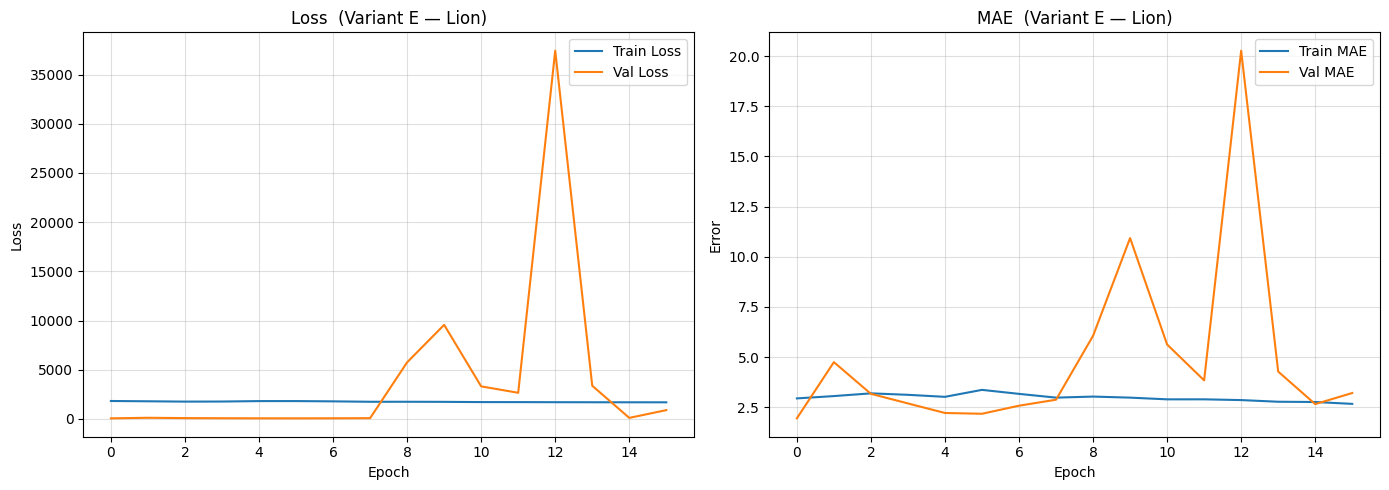

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 46s 2ms/step
Variant E — R²  : 0.0425
Variant E — MAE : 2.181917
Variant E — MSE : 55.144113


In [102]:
#  Evaluate 

plot_training_history(history_lion, title="(Variant E — Lion)")

y_pred_cnn_lion = cnn_yahoo_lion.predict(X_yahoo_test_scaled).ravel()
print(f"Variant E — R²  : {r2_score(y_yahoo_test, y_pred_cnn_lion):.4f}")
print(f"Variant E — MAE : {mean_absolute_error(y_yahoo_test, y_pred_cnn_lion):.6f}")
print(f"Variant E — MSE : {mean_squared_error(y_yahoo_test, y_pred_cnn_lion):.6f}")


### 7.2 — Windowed 1D-CNN on Time-Series Sequences (Yahoo Finance)

The best CNN variant is re-trained on **sliding windows of 30 time steps**, allowing the model to capture sequential patterns across recent history rather than treating each row independently.

Data is prepared using `tf.keras.utils.timeseries_dataset_from_array`.


In [103]:
# Sliding Window Dataset Construction 

WINDOW_SIZE = 30
BATCH_SIZE  = 512

yahoo_train_win = tf.keras.utils.timeseries_dataset_from_array(
    data     = X_yahoo_train_scaled,
    targets  = y_yahoo_train.values[WINDOW_SIZE:],
    sequence_length=WINDOW_SIZE,
    batch_size=None,
).batch(BATCH_SIZE, drop_remainder=True)

yahoo_test_win = tf.keras.utils.timeseries_dataset_from_array(
    data     = X_yahoo_test_scaled,
    targets  = y_yahoo_test.values[WINDOW_SIZE:],
    sequence_length=WINDOW_SIZE,
    batch_size=None,
).batch(BATCH_SIZE, drop_remainder=True)

for x_batch, y_batch in yahoo_train_win.take(1):
    print(f"Batch X shape : {x_batch.shape}  (batch, window, features)")
    print(f"Batch y shape : {y_batch.shape}")


Batch X shape : (512, 30, 12)  (batch, window, features)
Batch y shape : (512,)


In [104]:
#  Build Windowed CNN 

n_features = X_yahoo_train_scaled.shape[1]

cnn_yahoo_win = models.Sequential([
        layers.Conv1D(32, 8, activation="leaky_relu", padding="same",input_shape=(WINDOW_SIZE, n_features)),
        layers.BatchNormalization(),

        layers.Conv1D(64, 8, activation="softplus", padding="same"),
        layers.MaxPooling1D(pool_size=2),

        layers.Conv1D(64, 8, activation="relu", padding="same"),
        layers.BatchNormalization(),

        layers.Flatten(),
        layers.Dense(32, activation="leaky_relu"),
        layers.Dense(1),
    ])


In [105]:
#  Compile 

cnn_yahoo_win.compile(
    optimizer=keras.optimizers.Adam(learning_rate=keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=0.001,
        decay_steps=10000,
        decay_rate=0.9)),
    loss='huber',
    metrics=['mae'],
)

In [106]:
display(cnn_yahoo_win.summary())

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_19 (Conv1D)              │ (None, 30, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 30, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_20 (Conv1D)              │ (None, 30, 64)         │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_21 (Conv1D)              │ (None, 15, 64)         │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 15, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │        30,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,553 (326.38 KB)

 Trainable params: 83,361 (325.63 KB)

 Non-trainable params: 192 (768.00 B)

None

In [107]:
#  Train 

history_win = cnn_yahoo_win.fit(
    yahoo_train_win,
    validation_data=yahoo_test_win,
    epochs = 20,
    batch_size = 512,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        patience=10,
        monitor='val_loss',
        restore_best_weights=True),
    ]
)


Epoch 1/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 328s 49ms/step - loss: 3.1439 - mae: 3.5520 - val_loss: 1.4104 - val_mae: 1.8079
Epoch 2/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 321s 49ms/step - loss: 3.1391 - mae: 3.5472 - val_loss: 1.4097 - val_mae: 1.8087
Epoch 3/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 330s 50ms/step - loss: 3.1389 - mae: 3.5470 - val_loss: 1.4097 - val_mae: 1.8084
Epoch 4/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 332s 51ms/step - loss: 3.1389 - mae: 3.5470 - val_loss: 1.4097 - val_mae: 1.8078
Epoch 5/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 329s 50ms/step - loss: 3.1389 - mae: 3.5470 - val_loss: 1.4097 - val_mae: 1.8079
Epoch 6/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 323s 49ms/step - loss: 3.1389 - mae: 3.5470 - val_loss: 1.4097 - val_mae: 1.8078
Epoch 7/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 321s 49ms/step - loss: 3.1388 - mae: 3.5470 - val_loss: 1.4097 - val_mae: 1.8079
Epoch 8/20
6574/6574 ━━━━━━━━━━━━━━━━━━━━ 327s 50ms/step - loss: 3.1388 - mae: 3.5469 - val_loss: 1.4098 - val_mae: 1.8079
Epoch 9/20
6574/

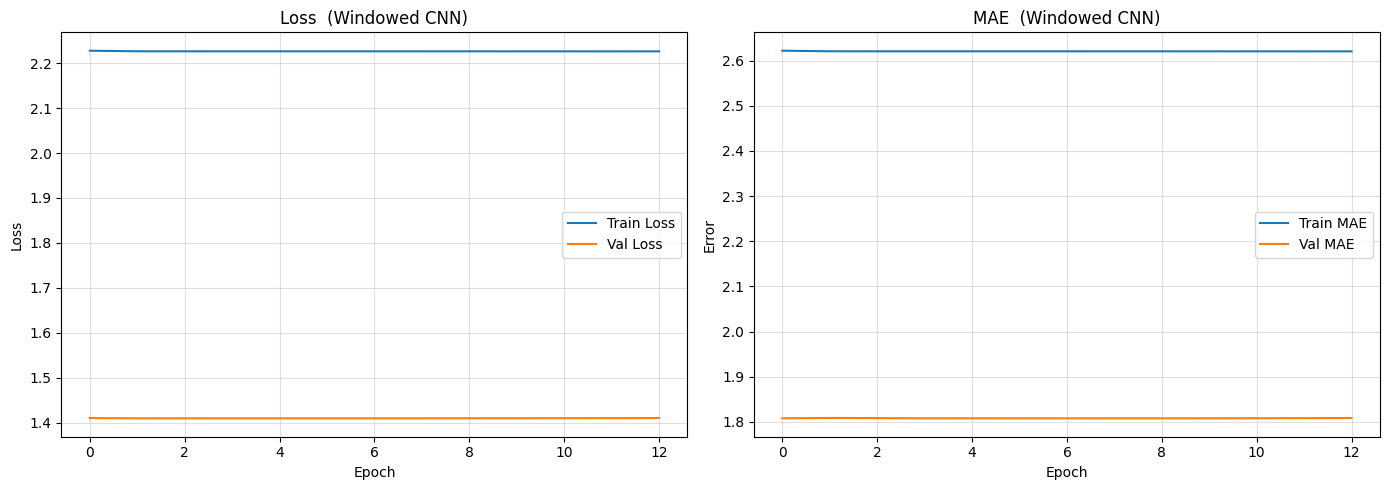

Windowed CNN training complete.


In [108]:
#  Evaluate 

plot_training_history(history_win, title="(Windowed CNN)")
print("Windowed CNN training complete.")


In [109]:
yahoo_cnn1_arch = cnn_yahoo_linear2
y_yahoo_pred = yahoo_cnn1_arch.predict(X_yahoo_test_scaled).reshape(-1)

26301/26301 ━━━━━━━━━━━━━━━━━━━━ 43s 2ms/step


In [110]:
errors = []
i = 0
while i < y_yahoo_pred.shape[0]:
    errors.append(np.abs(y_yahoo_pred[i] - y_yahoo_test.iloc[i]))
    i += 1
errors = np.array(errors)


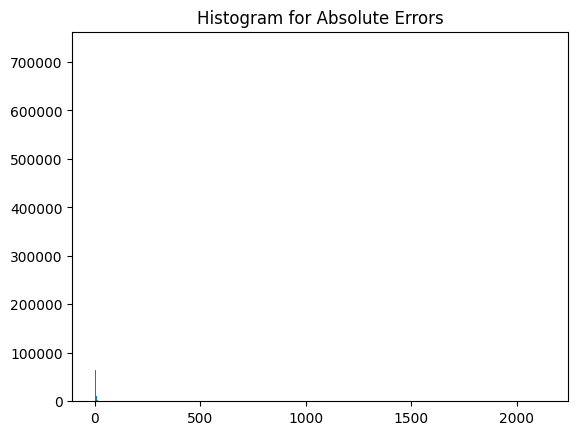

3.3552136395886833e-06 726269.0
2.137443282301037 64378.0
4.274883209388434 21376.0
6.41232313647583 9879.0
8.549763063563228 5410.0
10.687202990650626 3342.0
12.824642917738021 2142.0
14.962082844825419 1556.0
17.099522771912817 1108.0
19.236962699000212 809.0
21.374402626087612 732.0
23.511842553175008 540.0
25.649282480262404 443.0
27.786722407349803 360.0
29.9241623344372 347.0
32.0616022615246 253.0
34.199042188612 200.0
36.3364821156994 196.0
38.47392204278679 185.0
40.61136196987419 146.0
42.74880189696159 129.0
44.88624182404898 131.0
47.02368175113638 120.0
49.16112167822378 93.0
51.29856160531117 75.0
53.43600153239857 78.0
55.57344145948597 80.0
57.71088138657337 71.0
59.84832131366076 70.0
61.98576124074816 71.0
64.12320116783555 51.0
66.26064109492295 47.0
68.39808102201035 46.0
70.53552094909774 45.0
72.67296087618514 40.0
74.81040080327254 51.0
76.94784073035993 41.0
79.08528065744733 24.0
81.22272058453473 24.0
83.36016051162213 35.0
85.49760043870953 19.0
87.6350403657

In [111]:
counts, bins, _ = plt.hist(errors, bins=1000)
plt.title("Histogram for Absolute Errors")
plt.show()
for bn, count in zip(bins[:100], counts[:100]):
    print(bn, count)


In [112]:
cnn_results = {
    "Variant A (LeakyReLU + ExpDecay)": (y_pred_cnn_A,    y_yahoo_test),
    "Variant B (ReLU + AdamW)"        : (y_pred_cnn_B,    y_yahoo_test),
    "Variant C (Deeper + 2x MaxPool)" : (y_pred_cnn_C,    y_yahoo_test),
    "Variant D (RMSprop)"             : (y_pred_cnn_rms,  y_yahoo_test),
    "Variant E (Lion)"                : (y_pred_cnn_lion, y_yahoo_test),
}

### 7.3 — Transfer Learning: AAPL → TSLA (Yahoo Finance)

A 1D-CNN is first trained from scratch on **AAPL** (source stock). Its convolutional layers are then **frozen** and the model is fine-tuned on **TSLA** (target stock) — simulating knowledge transfer across assets.

**Rationale:** Feature patterns like momentum and volatility regimes are likely to be shared across stocks in the same market.


In [113]:
yahoo_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4208032 entries, 0 to 4208031
Data columns (total 24 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Date            object 
 1   Open            float64
 2   High            float64
 3   Low             float64
 4   Close           float64
 5   Volume          int64  
 6   Dividends       float64
 7   Stock Splits    float64
 8   Ticker          object 
 9   returns         float64
 10  rolling_mean_7  float64
 11  rolling_std_7   float64
 12  MA_5            float64
 13  MA_10           float64
 14  Daily_Return    float64
 15  RSI_14          float64
 16  MACD_Line       float64
 17  MACD_Signal     float64
 18  MACD_Hist       float64
 19  ATR             float64
 20  lag_1           float64
 21  lag_2           float64
 22  Volatility_10   float64
 23  target_price    float64
dtypes: float64(21), int64(1), object(2)
memory usage: 770.5+ MB


In [114]:
print(yahoo_data['Ticker'].unique())

['MSI' 'BA' 'KR' 'IBM' 'IP' 'GD' 'DIS' 'MO' 'MRK' 'DTE' 'HPQ' 'MMM' 'CVX'
 'JNJ' 'ED' 'CAT' 'PG' 'AEP' 'KO' 'XOM' 'GE' 'HON' 'CNP' 'MRO' 'RTX' 'MCD'
 'PCG' 'AXP' 'ETN' 'PFE' 'LLY' 'DD' 'TXN' 'BMY' 'ETR' 'DE' 'EMR' 'HAL' 'F'
 'WFC' 'PEP' 'WMT' 'AIG' 'TER' 'MKC' 'EVRG' 'NEE' 'TXT' 'CVS' 'CLX' 'PNW'
 'LNT' 'BALL' 'GWW' 'XEL' 'WHR' 'SPGI' 'SNA' 'VMC' 'AVY' 'TGT' 'RVTY'
 'CMS' 'BDX' 'BAC' 'ECL' 'K' 'MMC' 'NI' 'ES' 'CMI' 'CPB' 'ITW' 'EXC' 'CL'
 'MDT' 'WY' 'BK' 'PNR' 'FRT' 'USB' 'EIX' 'SYY' 'WRB' 'IFF' 'TAP' 'TRV'
 'PNC' 'C' 'LMT' 'FDX' 'WDC' 'DHR' 'APA' 'LUV' 'PEG' 'UNP' 'BIO' 'RHI'
 'HSY' 'GPC' 'MTB' 'SYK' 'SEE' 'APD' 'CAG' 'FMC' 'ALK' 'EFX' 'CHD' 'TSN'
 'RF' 'ADP' 'STT' 'VFC' 'LOW' 'EQT' 'TFX' 'DUK' 'CMA' 'HES' 'ADI' 'VTRS'
 'HRL' 'CINF' 'INTC' 'D' 'FITB' 'IPG' 'HAS' 'NUE' 'DOV' 'NTRS' 'NEM' 'LEN'
 'TMO' 'HST' 'ABT' 'PCAR' 'ADM' 'PH' 'PPG' 'ROL' 'L' 'PGR' 'CMCSA' 'WST'
 'SHW' 'TT' 'ZION' 'SWK' 'OMC' 'WEC' 'AMD' 'AFL' 'GIS' 'PHM' 'KMB' 'PPL'
 'AMAT' 'JPM' 'HBAN' 'BF-B' 'J' 'WBA' 'MAS' 'TYL'

In [115]:
yahoo_data['Daily_Return'].head()

0     1.402307
1    -0.697035
2    -0.823727
3    45.749814
4    -0.413035
Name: Daily_Return, dtype: float64

In [116]:
#  Prepare Source Data (AAPL) 

SOURCE_TICKER = "AAPL"

TL_FEATURES = [
    "Volume",
    "MA_5", "MA_10", "Daily_Return",
    "RSI_14", "MACD_Line", "MACD_Signal", "MACD_Hist",
    "lag_1", "lag_2", "Volatility_10",
]

df_aapl = yahoo_data[yahoo_data["Ticker"] == SOURCE_TICKER].sort_values("Date")

X_aapl = StandardScaler().fit_transform(df_aapl[TL_FEATURES].values)
y_aapl = df_aapl["returns"].values


def make_sequences(X: np.ndarray, y: np.ndarray, window: int = 30):
    """Convert a feature matrix into overlapping sliding-window sequences."""
    X_seq = np.array([X[i : i + window] for i in range(len(X) - window)])
    y_seq = np.array([y[i + window]     for i in range(len(X) - window)])
    return X_seq, y_seq


X_aapl_seq, y_aapl_seq = make_sequences(X_aapl, y_aapl)

split = int(0.8 * len(X_aapl_seq))
X_aapl_train, X_aapl_test = X_aapl_seq[:split], X_aapl_seq[split:]
y_aapl_train, y_aapl_test = y_aapl_seq[:split], y_aapl_seq[split:]

print(f"AAPL — train : {X_aapl_train.shape}, test : {X_aapl_test.shape}")


AAPL — train : (8603, 30, 11), test : (2151, 30, 11)


In [117]:
#  Build Source Model 

n_tl_features = X_aapl_train.shape[2]

tl_source_model = Sequential(
    [
        Conv1D(64, 3, activation="relu", input_shape=(30, n_tl_features)),
        MaxPooling1D(2),

        Conv1D(128, 3, activation="relu"),
        MaxPooling1D(2),

        Flatten(),
        Dense(50, activation="relu"),
        Dropout(0.2),
        Dense(1),
    ])


In [118]:
#  Compile Source Model 

tl_source_model.compile(
    optimizer="adam", 
    loss="mse", 
    metrics=["mae"]
)

tl_source_model.summary()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_22 (Conv1D)              │ (None, 28, 64)         │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_23 (Conv1D)              │ (None, 12, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_9 (MaxPooling1D)  │ (None, 6, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 50)             │        38,450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,381 (255.39 KB)

 Trainable params: 65,381 (255.39 KB)

 Non-trainable params: 0 (0.00 B)

In [119]:
#  Train Source Model on AAPL 

history_tl_source = tl_source_model.fit(
    X_aapl_train, y_aapl_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_aapl_test, y_aapl_test),
    verbose=1,
)


Epoch 1/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.0082 - mae: 0.0483 - val_loss: 4.0284e-04 - val_mae: 0.0136
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.4997e-04 - mae: 0.0214 - val_loss: 3.9216e-04 - val_mae: 0.0134
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.2407e-04 - mae: 0.0210 - val_loss: 3.4515e-04 - val_mae: 0.0130
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.1080e-04 - mae: 0.0212 - val_loss: 3.4419e-04 - val_mae: 0.0130
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.0198e-04 - mae: 0.0211 - val_loss: 3.4472e-04 - val_mae: 0.0130
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.5045e-04 - mae: 0.0207 - val_loss: 3.4535e-04 - val_mae: 0.0130
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.7261e-04 - mae: 0.0209 - val_loss: 3.4604e-04 - val_mae: 0.0130
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8.8644e-04 - mae: 0.0211 - val_loss: 3.5027e-04 - val_mae: 0.

In [120]:
#  Evaluate Source Model (AAPL) 

y_pred_aapl = tl_source_model.predict(X_aapl_test).ravel()

mse_source  = mean_squared_error(y_aapl_test, y_pred_aapl)
mae_source  = mean_absolute_error(y_aapl_test, y_pred_aapl)
r2_source   = r2_score(y_aapl_test, y_pred_aapl)

print("=== Source Model — AAPL (Cold Start) ===")
print(f"R²   : {r2_source:.4f}")
print(f"MAE  : {mae_source:.6f}")
print(f"MSE  : {mse_source:.6f}")
print(f"RMSE : {np.sqrt(mse_source):.6f}")


68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
=== Source Model — AAPL (Cold Start) ===
R²   : -0.0299
MAE  : 0.013071
MSE  : 0.000352
RMSE : 0.018766


In [121]:
#  Freeze Convolutional Layers 

for layer in tl_source_model.layers[:-2]:
    layer.trainable = False

trainable_params = sum(
    p.numpy().size for p in tl_source_model.trainable_variables
)
print(f"Trainable parameters after freezing : {trainable_params:,}")


Trainable parameters after freezing : 51


In [122]:
#  Prepare Target Data (TSLA) 

TARGET_TICKER = "TSLA"

df_tsla = yahoo_data[yahoo_data["Ticker"] == TARGET_TICKER].sort_values("Date")

X_tsla = StandardScaler().fit_transform(df_tsla[TL_FEATURES].values)
y_tsla = df_tsla["Daily_Return"].values

X_tsla_seq, y_tsla_seq = make_sequences(X_tsla, y_tsla)

split_t = int(0.8 * len(X_tsla_seq))
X_tsla_train, X_tsla_test = X_tsla_seq[:split_t], X_tsla_seq[split_t:]
y_tsla_train, y_tsla_test = y_tsla_seq[:split_t], y_tsla_seq[split_t:]

print(f"TSLA — train : {X_tsla_train.shape}, test : {X_tsla_test.shape}")


TSLA — train : (2640, 30, 11), test : (661, 30, 11)


In [123]:
#  Fine-Tune on TSLA 

tl_source_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_tl_finetune = tl_source_model.fit(
    X_tsla_train, y_tsla_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_tsla_test, y_tsla_test),
    verbose=1,
)


Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 1.0887 - mae: 0.7826 - val_loss: 20.5237 - val_mae: 2.7160
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.1383 - mae: 0.7396 - val_loss: 20.9063 - val_mae: 2.7676
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7715 - mae: 0.6443 - val_loss: 21.2644 - val_mae: 2.8174
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8933 - mae: 0.6274 - val_loss: 21.5778 - val_mae: 2.8621
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8141 - mae: 0.5689 - val_loss: 21.8712 - val_mae: 2.9044
Epoch 6/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7091 - mae: 0.5333 - val_loss: 22.1190 - val_mae: 2.9405
Epoch 7/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6608 - mae: 0.4981 - val_loss: 22.3404 - val_mae: 2.9731
Epoch 8/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8531 - mae: 0.4943 - val_loss: 22.5187 - val_mae: 2.9996
Epoch 9/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.694

In [124]:
#  Evaluate Fine-Tuned Model (TSLA) 

y_pred_tsla = tl_source_model.predict(X_tsla_test).ravel()

mse_fine  = mean_squared_error(y_tsla_test, y_pred_tsla)
mae_fine  = mean_absolute_error(y_tsla_test, y_pred_tsla)
r2_fine   = r2_score(y_tsla_test, y_pred_tsla)

print("=== Fine-Tuned Model — TSLA ===")
print(f"R²   : {r2_fine:.4f}")
print(f"MAE  : {mae_fine:.6f}")
print(f"MSE  : {mse_fine:.6f}")
print(f"RMSE : {np.sqrt(mse_fine):.6f}")


21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
=== Fine-Tuned Model — TSLA ===
R²   : -0.6693
MAE  : 3.041303
MSE  : 22.800005
RMSE : 4.774935


In [125]:
#  Transfer Learning Comparison Summary 

tl_summary = pd.DataFrame({
    "Metric" : ["MSE", "RMSE", "MAE", "R²"],
    "AAPL — Cold Start": [
        mse_source, np.sqrt(mse_source), mae_source, r2_source,
    ],
    "TSLA — Fine-Tuned": [
        mse_fine, np.sqrt(mse_fine), mae_fine, r2_fine,
    ],
})

print(tl_summary.to_string(index=False))


Metric  AAPL — Cold Start  TSLA — Fine-Tuned
   MSE           0.000352          22.800005
  RMSE           0.018766           4.774935
   MAE           0.013071           3.041303
    R²          -0.029937          -0.669311


### 7.4 — AutoEncoder for Anomaly / Fraud Detection (Credit Card)

An AutoEncoder is trained **exclusively on normal (non-fraud) transactions**. It learns to reconstruct the patterns of legitimate behaviour.

At inference time, fraud transactions produce higher reconstruction errors. A threshold at the **99th percentile** of training reconstruction errors is used to separate normal from anomalous transactions.

**Architecture:** Input → 16 → 8 (bottleneck) → 8 → 16 → Input  
**Evaluation:** Classification report + reconstruction error visualisation + ROC-AUC curve


In [126]:
#  Isolate Normal Transactions for Training 

X_train_normal = X_fraud_train_scaled[y_fraud_train.values == 0]
X_train_fraud  = X_fraud_train_scaled[y_fraud_train.values == 1]
y_train_fraud  = y_fraud_train.values[y_fraud_train.values == 1]

# Rescue training-set fraud samples into the test set to improve evaluation coverage
X_ae_test = np.vstack([X_fraud_test_scaled, X_train_fraud])
y_ae_test  = np.concatenate([y_fraud_test.values, y_train_fraud])

print(f"Normal training samples : {X_train_normal.shape[0]:,}")
print(f"Extended test samples   : {X_ae_test.shape[0]:,}")
print(f"Fraud in test set       : {y_ae_test.sum():,}")


Normal training samples : 226,602
Extended test samples   : 57,124
Fraud in test set       : 473


In [127]:
#  Build AutoEncoder 

input_dim   = X_train_normal.shape[1]
input_layer = Input(shape=(input_dim,), name="input")

# Encoder
encoded = Dense(16, activation="relu", name="enc_16")(input_layer)
encoded = Dense(8,  activation="relu", name="enc_8")(encoded)

# Decoder
decoded = Dense(8,  activation="relu", name="dec_8")(encoded)
decoded = Dense(16, activation="relu", name="dec_16")(decoded)
decoded = Dense(input_dim, activation="linear", name="output")(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded, name="AutoEncoder_Fraud")


In [128]:
#  Compile 

autoencoder.compile(
optimizer="adam", 
loss="mean_squared_error"
)

autoencoder.summary()


Model: "AutoEncoder_Fraud"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_16 (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_8 (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_8 (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_16 (Dense)                  │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 32)             │           544 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,424 (5.56 KB)

 Trainable params: 1,424 (5.56 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
#  Train on Normal Transactions Only 

ae_history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=50,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,
    verbose=1,
)


Epoch 1/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - loss: 0.7802 - val_loss: 0.5972
Epoch 2/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.6026 - val_loss: 0.5616
Epoch 3/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5732 - val_loss: 0.5341
Epoch 4/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5439 - val_loss: 0.5251
Epoch 5/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5319 - val_loss: 0.5211
Epoch 6/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5305 - val_loss: 0.5189
Epoch 7/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5239 - val_loss: 0.5125
Epoch 8/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - loss: 0.5150 - val_loss: 0.5092
Epoch 9/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5164 - val_loss: 0.5054
Epoch 10/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5056 - val_loss: 0.4960
Epoch 11/50
6374/6374 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.5025 - val_loss: 0.4914
Epoch 12/50
6374/63

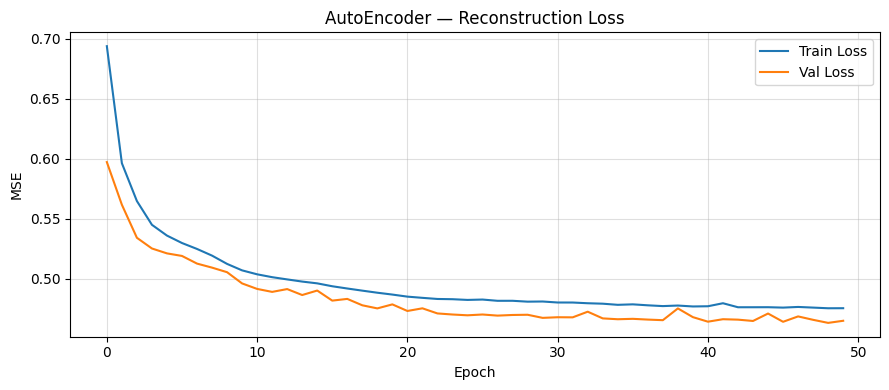

In [130]:
#  Plot Training Loss 

plt.figure(figsize=(9, 4))
plt.plot(ae_history.history["loss"],     label="Train Loss")
plt.plot(ae_history.history["val_loss"], label="Val Loss")
plt.title("AutoEncoder — Reconstruction Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


In [131]:
#  Compute Threshold from Normal Training Reconstruction Error 

train_reconstructions = autoencoder.predict(X_train_normal, verbose=0)
mse_train = np.mean(np.power(X_train_normal - train_reconstructions, 2), axis=1)

ae_threshold = np.percentile(mse_train, 99)
print(f"Anomaly threshold (99th percentile) : {ae_threshold:.6f}")


Anomaly threshold (99th percentile) : 2.288770


In [132]:
#  Evaluate on Test Set 

test_reconstructions = autoencoder.predict(X_ae_test, verbose=0)
mse_test = np.mean(np.power(X_ae_test - test_reconstructions, 2), axis=1)

y_ae_pred = (mse_test > ae_threshold).astype(int)

print("=== AutoEncoder — Anomaly Detection ===")
print(classification_report(y_ae_test, y_ae_pred, target_names=["Legitimate", "Fraud"]))


=== AutoEncoder — Anomaly Detection ===
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99     56651
       Fraud       0.38      0.78      0.51       473

    accuracy                           0.99     57124
   macro avg       0.69      0.88      0.75     57124
weighted avg       0.99      0.99      0.99     57124



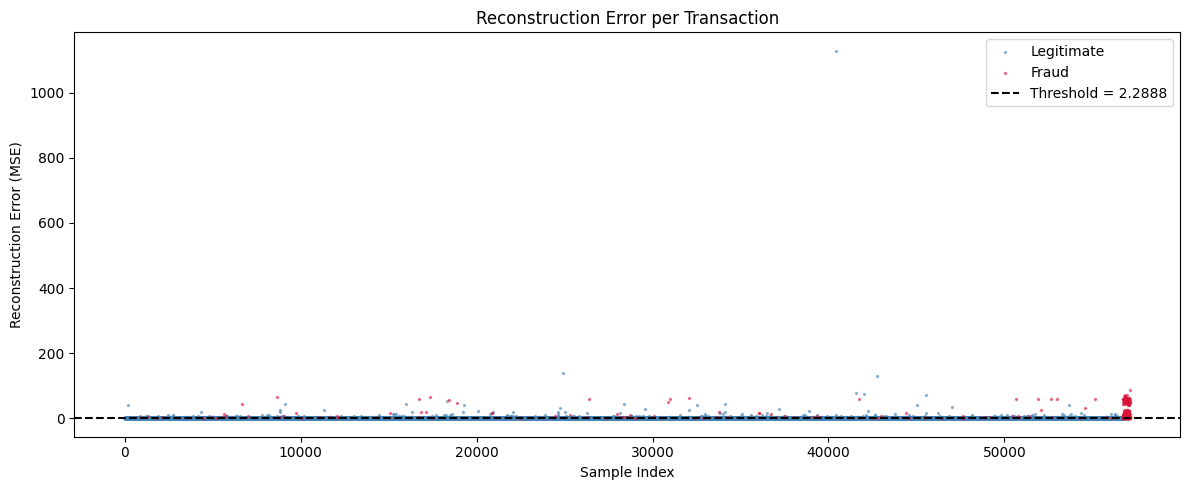

In [133]:
#  Reconstruction Error Visualisation 

error_df = pd.DataFrame({
    "reconstruction_error": mse_test,
    "true_class"          : y_ae_test,
})

fig, ax = plt.subplots(figsize=(12, 5))
for cls, label, color in [(0, "Legitimate", "steelblue"), (1, "Fraud", "crimson")]:
    subset = error_df[error_df["true_class"] == cls]
    ax.scatter(subset.index, subset["reconstruction_error"],
               label=label, s=2, alpha=0.5, color=color)

ax.axhline(ae_threshold, color="black", linestyle="--", lw=1.5, label=f"Threshold = {ae_threshold:.4f}")
ax.set_title("Reconstruction Error per Transaction")
ax.set_xlabel("Sample Index")
ax.set_ylabel("Reconstruction Error (MSE)")
ax.legend()
plt.tight_layout()
plt.show()


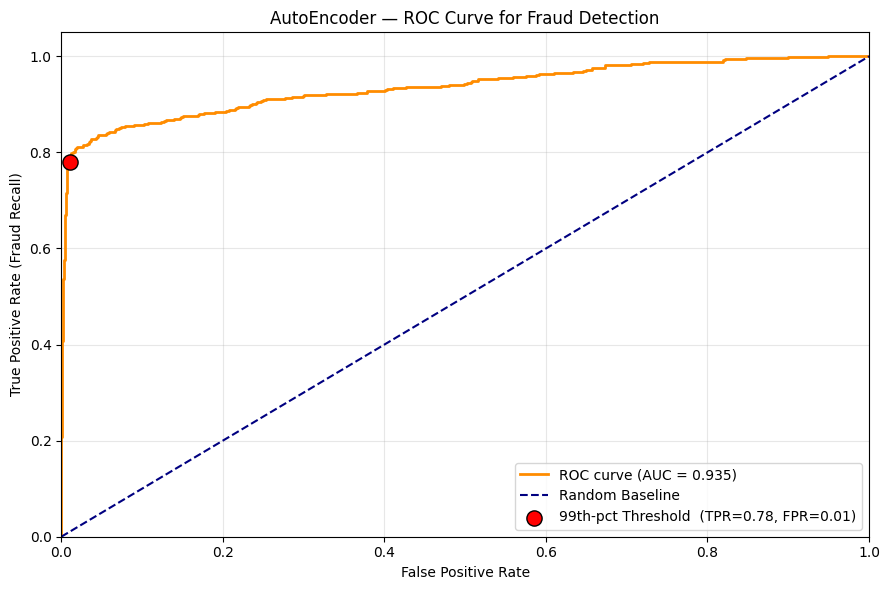

ROC-AUC : 0.9354
Threshold 2.2888  →  TPR: 0.780, FPR: 0.011


In [134]:
#  ROC-AUC Curve 

fpr_ae, tpr_ae, thresholds_ae = roc_curve(y_ae_test, mse_test)
roc_auc_ae = auc(fpr_ae, tpr_ae)

# Mark where the chosen threshold sits on the ROC curve
tpr_at_threshold = np.mean(mse_test[y_ae_test == 1] > ae_threshold)
fpr_at_threshold = np.mean(mse_test[y_ae_test == 0] > ae_threshold)

plt.figure(figsize=(9, 6))
plt.plot(fpr_ae, tpr_ae, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc_ae:.3f})")
plt.plot([0, 1], [0, 1], "navy", lw=1.5, linestyle="--", label="Random Baseline")
plt.scatter(
    fpr_at_threshold, tpr_at_threshold,
    color="red", s=120, zorder=5, edgecolors="black",
    label=f"99th-pct Threshold  (TPR={tpr_at_threshold:.2f}, FPR={fpr_at_threshold:.2f})"
)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.title("AutoEncoder — ROC Curve for Fraud Detection")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Fraud Recall)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC : {roc_auc_ae:.4f}")
print(f"Threshold {ae_threshold:.4f}  →  TPR: {tpr_at_threshold:.3f}, FPR: {fpr_at_threshold:.3f}")


---
## Step 8 — Final Results Summary

A consolidated view of all models across both phases and all three datasets.


In [135]:
#  Phase 1: Classical ML Summary

print("=" * 60)
print("PHASE 1 — CLASSICAL ML")
print("=" * 60)

print("\n[Naïve Bayes — Fraud Detection]")
print(f"  Baseline  AUC : {roc_auc_nb:.4f}")
print(f"  PCA       AUC : {roc_auc_pca:.4f}")

print("\n[KNN — Crypto Return Regression]")
print(f"  Full Features  R² : {test_r2:.4f}  |  MAE : {test_mae:.6f}")
print(f"  PCA-Reduced    R² : {test_r2_pca:.4f}  |  MAE : {test_mae_pca:.6f}")

print("\n[Ensemble — Yahoo Finance Stock Return Regression]")
print(f"  Random Forest  R² :  {r2_score(y_stock_test, rf_predictions):.4f}  |  MSE : {mean_squared_error(y_stock_test, rf_predictions):.6f}")
print(f"  XGBoost        R² : {r2_score(y_stock_test, xgb_predictions):.4f}  |  MSE : {mean_squared_error(y_stock_test, xgb_predictions):.6f}")


print("\n" + "=" * 60)
print("PHASE 2 — DEEP LEARNING")
print("=" * 60)

print("\n[1D-CNN — Yahoo Finance Stock Return Regression]")
for name, (pred, true) in cnn_results.items():
    print(f"  {name}  R² : {r2_score(true, pred):.4f}  |  MSE : {mean_squared_error(true, pred):.6f}")

print("\n[Transfer Learning — AAPL → TSLA]")
print(f"  AAPL Cold Start  R² : {r2_source:.4f}  |  MSE : {mse_source:.6f}")
print(f"  TSLA Fine-Tuned  R² : {r2_fine:.4f}  |  MSE : {mse_fine:.6f}")

print("\n[AutoEncoder — Fraud / Anomaly Detection]")
print(f"  Threshold (99th pct) : {ae_threshold:.6f}")
print(f"  ROC-AUC              : {roc_auc_ae:.4f}")
print(f"  TPR (Fraud Recall)   : {tpr_at_threshold:.3f}")
print(f"  FPR (False Alarm)    : {fpr_at_threshold:.3f}")


PHASE 1 — CLASSICAL ML

[Naïve Bayes — Fraud Detection]
  Baseline  AUC : 0.9468
  PCA       AUC : 0.9389

[KNN — Crypto Return Regression]
  Full Features  R² : -0.0750  |  MAE : 0.076771
  PCA-Reduced    R² : 0.0195  |  MAE : 0.072854

[Ensemble — Yahoo Finance Stock Return Regression]
  Random Forest  R² :  -0.1251  |  MSE : 2.213727
  XGBoost        R² : -0.1844  |  MSE : 2.330425

PHASE 2 — DEEP LEARNING

[1D-CNN — Yahoo Finance Stock Return Regression]
  Variant A (LeakyReLU + ExpDecay)  R² : 0.0803  |  MSE : 52.971213
  Variant B (ReLU + AdamW)  R² : 0.0739  |  MSE : 53.334763
  Variant C (Deeper + 2x MaxPool)  R² : 0.0854  |  MSE : 52.674772
  Variant D (RMSprop)  R² : 0.0732  |  MSE : 53.380284
  Variant E (Lion)  R² : 0.0425  |  MSE : 55.144113

[Transfer Learning — AAPL → TSLA]
  AAPL Cold Start  R² : -0.0299  |  MSE : 0.000352
  TSLA Fine-Tuned  R² : -0.6693  |  MSE : 22.800005

[AutoEncoder — Fraud / Anomaly Detection]
  Threshold (99th pct) : 2.288770
  ROC-AUC           